# Part (a): Data Cleaning and EDA
DSE4212 Group Project, Project 1: credit scoring on the Statlog German Credit data (UCI).

The data has 1,000 past loan applicants, 20 attributes and a good/bad credit label. Here we load and decode the data, check it for problems, look at how the variables are distributed and how they relate to default, and save a cleaned file (`data/processed/german_clean.csv`) for the later parts.

Throughout, `default = 1` means a bad credit risk. The raw file codes bad as 2 and good as 1.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt  # needs matplotlib >= 3.9 (boxplot tick_labels below)

pd.set_option("display.max_columns", 50, "display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
C_GOOD, C_BAD, C_NEUTRAL = "#4C72B0", "#C44E52", "#8C8C8C"

RAW = "data/raw/german.data"
OUT = "data/processed/german_clean.csv"

## 1. Load and decode
The raw file has no header row, so the column names come from `german.doc`. The categorical columns are stored as codes like A11 and A34. We replace them with their meanings so the plots (and the SHAP plots later) are readable.

In [3]:
COLS = ["checking", "duration", "credit_history", "purpose", "credit_amount", "savings",
        "employment", "installment_rate", "personal_status_sex", "other_debtors",
        "residence_since", "property", "age", "other_installment", "housing",
        "existing_credits", "job", "dependents", "telephone", "foreign_worker", "target"]

# code -> label, from german.doc
LABELS = {
    "checking": {"A11": "< 0 DM", "A12": "0-200 DM", "A13": ">= 200 DM", "A14": "no checking account"},
    "credit_history": {"A30": "no credits / all paid", "A31": "all paid at this bank",
                       "A32": "existing paid duly", "A33": "past delay",
                       "A34": "critical / other credits"},
    "purpose": {"A40": "car (new)", "A41": "car (used)", "A42": "furniture/equipment",
                "A43": "radio/TV", "A44": "domestic appliances", "A45": "repairs",
                "A46": "education", "A48": "retraining", "A49": "business", "A410": "others"},
    "savings": {"A61": "< 100 DM", "A62": "100-500 DM", "A63": "500-1000 DM",
                "A64": ">= 1000 DM", "A65": "unknown / none"},
    "employment": {"A71": "unemployed", "A72": "< 1 yr", "A73": "1-4 yrs",
                   "A74": "4-7 yrs", "A75": ">= 7 yrs"},
    "personal_status_sex": {"A91": "male: divorced/separated", "A92": "female: div/sep/married",
                            "A93": "male: single", "A94": "male: married/widowed"},
    "other_debtors": {"A101": "none", "A102": "co-applicant", "A103": "guarantor"},
    "property": {"A121": "real estate", "A122": "savings agmt / life insurance",
                 "A123": "car or other", "A124": "unknown / none"},
    "other_installment": {"A141": "bank", "A142": "stores", "A143": "none"},
    "housing": {"A151": "rent", "A152": "own", "A153": "for free"},
    "job": {"A171": "unemployed / unskilled non-resident", "A172": "unskilled resident",
            "A173": "skilled", "A174": "management / highly qualified"},
    "telephone": {"A191": "none", "A192": "yes"},
    "foreign_worker": {"A201": "yes", "A202": "no"},
}
CAT = list(LABELS)
NUM_CONT = ["duration", "credit_amount", "age"]                                  # continuous
NUM_DISC = ["installment_rate", "residence_since", "existing_credits", "dependents"]  # small-integer scales

raw = pd.read_csv(RAW, sep=" ", header=None, names=COLS)
print("shape:", raw.shape)
raw.head()

shape: (1000, 21)


,checking,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment,housing,existing_credits,job,dependents,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


In [4]:
numeric = raw.drop(columns="target").select_dtypes("number")
print(f"{numeric.shape[1]} numerical and {len(CAT)} categorical attributes (target excluded)")
numeric.nunique().sort_values().to_frame("distinct_values").T

7 numerical and 13 categorical attributes (target excluded)


,dependents,installment_rate,residence_since,existing_credits,duration,age,credit_amount
distinct_values,2,4,4,4,33,53,921


The file has 7 numerical and 13 categorical attributes, as in `german.doc`. Three of the numerical ones are continuous (`duration`, `credit_amount`, `age`). The other four take only 2 to 4 distinct values, so we treat them as ordinal scales.

## 2. Integrity checks
First we check that the file parsed properly: no nulls, no duplicates, and every code is in the code book (an unknown code would turn into NaN when we map it).

In [5]:
print("Missing cells      :", int(raw.isna().sum().sum()))
print("Duplicate rows     :", int(raw.duplicated().sum()))

unknown = {c: sorted(set(raw[c]) - set(LABELS[c])) for c in CAT if set(raw[c]) - set(LABELS[c])}
print("Undocumented codes :", unknown or "none")
assert raw["target"].isin([1, 2]).all()

Missing cells      : 0
Duplicate rows     : 0
Undocumented codes : none


In [6]:
df = raw.copy()
for c in CAT:
    df[c] = df[c].map(LABELS[c])
assert df[CAT].notna().all().all()

# target: 1 = bad (default), 0 = good
df["default"] = (df.pop("target") == 2).astype(int)

# sex can only be recovered from personal_status_sex (the doc lists A95 = female single, but it never appears)
df["sex"] = np.where(df["personal_status_sex"].str.startswith("female"), "female", "male")
df.dtypes.to_frame("dtype").T

,checking,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment,housing,existing_credits,job,dependents,telephone,foreign_worker,default,sex
dtype,object,int64,object,object,int64,object,object,int64,object,object,int64,object,int64,object,object,int64,object,int64,object,object,int64,object


### Consistency checks
Valid codes can still contradict each other, so we also test a few simple rules.

In [7]:
checks = {
    "'unemployed' but job = management/highly qualified": (df["employment"] == "unemployed") & (df["job"] == "management / highly qualified"),
    "age outside 18-100": ~df["age"].between(18, 100),
    "non-positive amount or duration": (df["credit_amount"] <= 0) | (df["duration"] <= 0),
}
pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="n_violations").to_frame()

,n_violations
'unemployed' but job = management/highly qualified,33
age outside 18-100,0
non-positive amount or duration,0


The range checks are clean. One exception is that 33 of the 62 "unemployed" applicants have job code A174. `german.doc` defines A174 as "management / self-employed / highly qualified employee / officer", and the label we use in the data is shortened and drops "self-employed". These are most likely self-employed people with no employer tenure, so we keep them.

## 3. Target and cost matrix
`german.doc` gives an asymmetric cost: approving a bad borrower costs 5, rejecting a good one costs 1.

In [8]:
vc = df["default"].value_counts().rename({0: "good (0)", 1: "bad (1)"})
print(pd.DataFrame({"n": vc, "share": (vc / len(df)).round(3)}))

# costs from german.doc: approving a bad loan = 5, rejecting a good one = 1
COST_BAD_APPROVED, COST_GOOD_REJECTED = 5, 1
p_bad = df["default"].mean()

# flag as bad when p * 5 > (1 - p) * 1, i.e. p > 1/6
cutoff = COST_GOOD_REJECTED / (COST_GOOD_REJECTED + COST_BAD_APPROVED)
print(f"\nCost-optimal decision threshold on P(bad): 1/6 = {cutoff:.3f}  (not 0.5)")
print(f"Naive 'approve everyone' cost per applicant: {p_bad * COST_BAD_APPROVED:.2f}   "
      f"vs 'reject everyone': {(1 - p_bad) * COST_GOOD_REJECTED:.2f}")

            n  share
default             
good (0)  700    0.7
bad (1)   300    0.3

Cost-optimal decision threshold on P(bad): 1/6 = 0.167  (not 0.5)
Naive 'approve everyone' cost per applicant: 1.50   vs 'reject everyone': 0.70


- The classes are 70/30. Always predicting "good" would already be 70% accurate, so accuracy is a poor metric. 
- With these costs the best cutoff on predicted P(bad) is 1/6, not 0.5, so the threshold needs tuning rather than using `.predict()` as is. This assumes the model's probabilities are well calibrated: with class weights or resampling they get shifted and 1/6 no longer applies directly.

## 4. Missing values
There are no NaNs, but a few categories mean "not available" (no checking account, unknown savings, unknown property). We check whether these behave like noise or carry information.

In [9]:
hidden = {"checking": "no checking account", "savings": "unknown / none", "property": "unknown / none"}
rows = []
for col, lvl in hidden.items():
    m = df[col] == lvl
    rows.append({"feature": col, "level": lvl, "n": m.sum(), "share": m.mean().round(3),
                 "default_rate_in_level": df.loc[m, "default"].mean().round(3),
                 "default_rate_elsewhere": df.loc[~m, "default"].mean().round(3)})
pd.DataFrame(rows)

,feature,level,n,share,default_rate_in_level,default_rate_elsewhere
0,checking,no checking account,394,0.394,0.117,0.419
1,savings,unknown / none,183,0.183,0.175,0.328
2,property,unknown / none,154,0.154,0.435,0.275


Three attributes use a category to mean “not available”: no checking account (39.4% of applicants), unknown savings (18.3%) and unknown property (15.4%). These reflect a genuinely missing account or asset, not random gaps, and they predict default (11.7%, 17.5% and 43.5%, against 30.0% overall), so we keep each as its own category instead of imputing it.

## 5. Numeric variables

In [10]:
desc = df[NUM_CONT + NUM_DISC].describe().T
desc["skew"] = df[NUM_CONT + NUM_DISC].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
duration,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0,1.09
credit_amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0,1.95
age,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0,1.02
installment_rate,1000.0,2.97,1.12,1.0,2.0,3.0,4.00,4.0,-0.53
residence_since,1000.0,2.84,1.10,1.0,2.0,3.0,4.00,4.0,-0.27
existing_credits,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0,1.27
dependents,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0,1.91


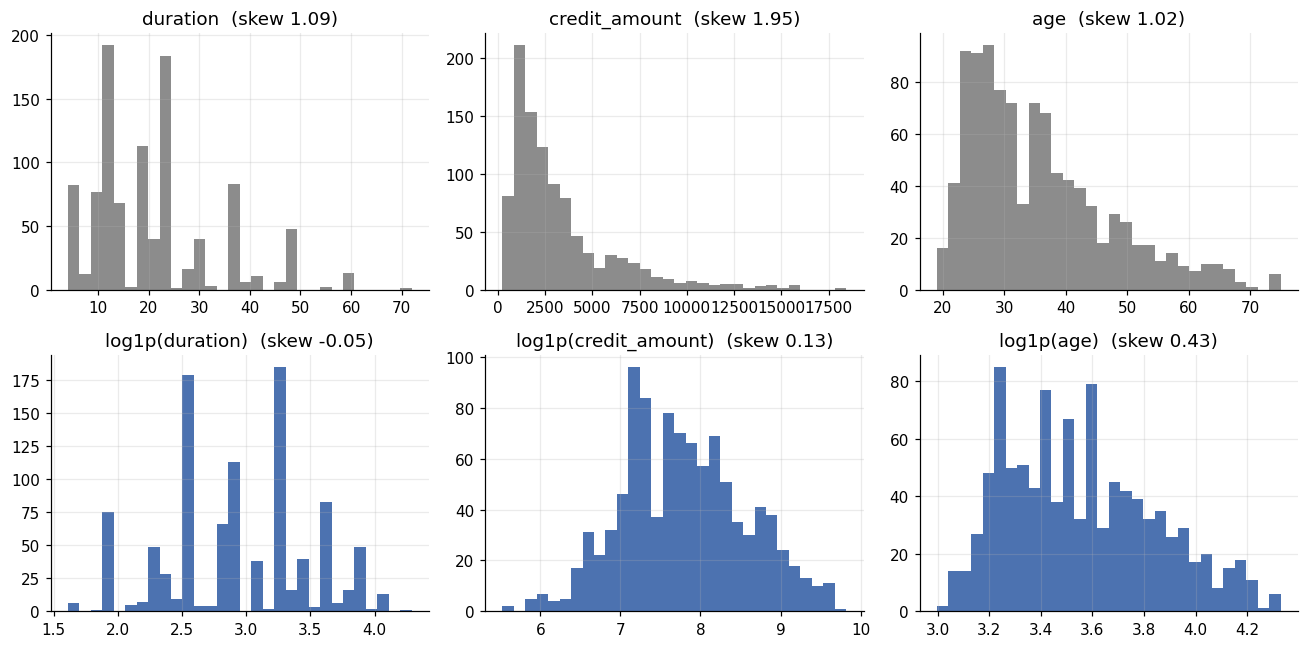

In [11]:
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for j, c in enumerate(NUM_CONT):
    ax[0, j].hist(df[c], bins=30, color=C_NEUTRAL)
    ax[0, j].set_title(f"{c}  (skew {df[c].skew():.2f})")
    lc = np.log1p(df[c])
    ax[1, j].hist(lc, bins=30, color=C_GOOD)
    ax[1, j].set_title(f"log1p({c})  (skew {lc.skew():.2f})")
plt.tight_layout(); plt.show()

`credit_amount` is strongly right-skewed (skew 1.9), and `duration` and `age` less so (about 1.0). After `log1p`, duration (-0.05) and credit_amount (0.13) are roughly symmetric. Age improves (1.02 to 0.43) but stays mildly right-skewed. We keep the original columns and add `log_*` versions: logistic regression can use the logged ones, tree models do not care about monotone transforms, and the original units are easier to read in SHAP plots. The four small-integer variables (installment rate, residence, existing credits, dependents) are left as they are.

In [12]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - k * i, q3 + k * i

rows = []
for c in NUM_CONT:
    lo, hi = iqr_bounds(df[c])
    out = (df[c] < lo) | (df[c] > hi)
    lo_l, hi_l = iqr_bounds(np.log1p(df[c]))
    out_log = (np.log1p(df[c]) < lo_l) | (np.log1p(df[c]) > hi_l)
    rows.append({"feature": c, "IQR upper fence": round(hi, 1), "n_outliers": out.sum(),
                 "n_outliers_after_log": out_log.sum(),
                 "default_rate_outliers": round(df.loc[out, "default"].mean(), 3),
                 "default_rate_rest": round(df.loc[~out, "default"].mean(), 3)})
pd.DataFrame(rows)

,feature,IQR upper fence,n_outliers,n_outliers_after_log,default_rate_outliers,default_rate_rest
0,duration,42.0,70,1,0.571,0.280
1,credit_amount,7882.4,72,1,0.542,0.281
2,age,64.5,23,0,0.261,0.301


TypeError: Axes.boxplot() got an unexpected keyword argument 'tick_labels'

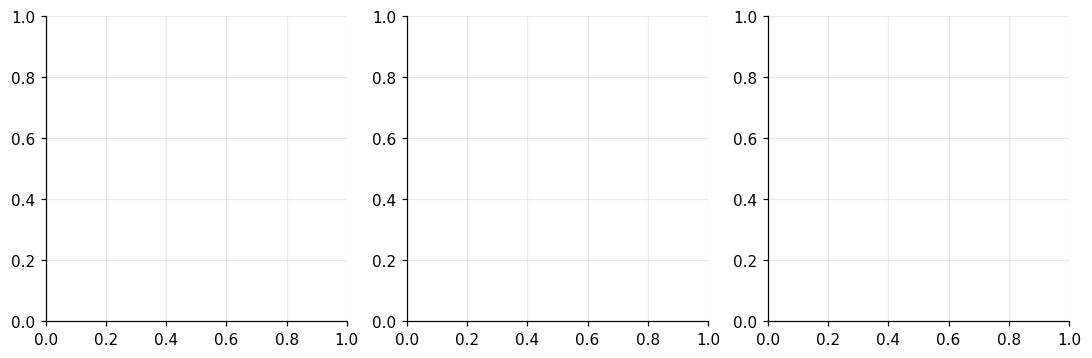

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, c in zip(ax, NUM_CONT):
    data = [df.loc[df["default"] == k, c] for k in (0, 1)]
    bp = a.boxplot(data, tick_labels=["good", "bad"], patch_artist=True, widths=.55,
                   medianprops={"color": "black"})
    for patch, col in zip(bp["boxes"], (C_GOOD, C_BAD)): patch.set_facecolor(col); patch.set_alpha(.7)
    a.set_title(c)
plt.tight_layout(); plt.show()

print("Largest loans:")
df.nlargest(6, "credit_amount")[["credit_amount", "duration", "purpose", "age", "default"]]

We keep all outliers.
- Dropping about 70 rows each for `duration` and `credit_amount` (7%) loses a lot of a small dataset, and they are not errors: they are large, long loans (business, etc.).
- Duration and amount outliers default at about 55% against 28% for the rest, so removing or clipping them would remove exactly the risky cases. Age outliers (23 rows) do not show this.
- After `log1p` only 1, 1 and 0 points are left outside the IQR fences, so the tail is already handled for linear models.

## 6. Categorical variables

In [ ]:
rare = [(c, l, n) for c in CAT for l, n in df[c].value_counts().items() if n < 30]
pd.DataFrame(rare, columns=["feature", "level", "n"])

,feature,level,n
0,purpose,repairs,22
1,purpose,domestic appliances,12
2,purpose,others,12
3,purpose,retraining,9
4,job,unemployed / unskilled non-resident,22


Five levels have fewer than 30 applicants: purpose = retraining (9), domestic appliances (12), others (12), repairs (22), and job = unemployed/unskilled non-resident (22). The cutoff of 30 is a judgement call: nine more levels have only 37-52 rows (e.g. other_debtors co-applicant 41 and guarantor 52, credit_history no credits / all paid 40, foreign_worker = no 37), so they may also be unstable. Default rates on so few cases are unreliable, and some CV folds may have none of them. We leave them for now and merge them in part (b) using a fixed mapping, applied before the train/test split.

## 7. Relationship with default

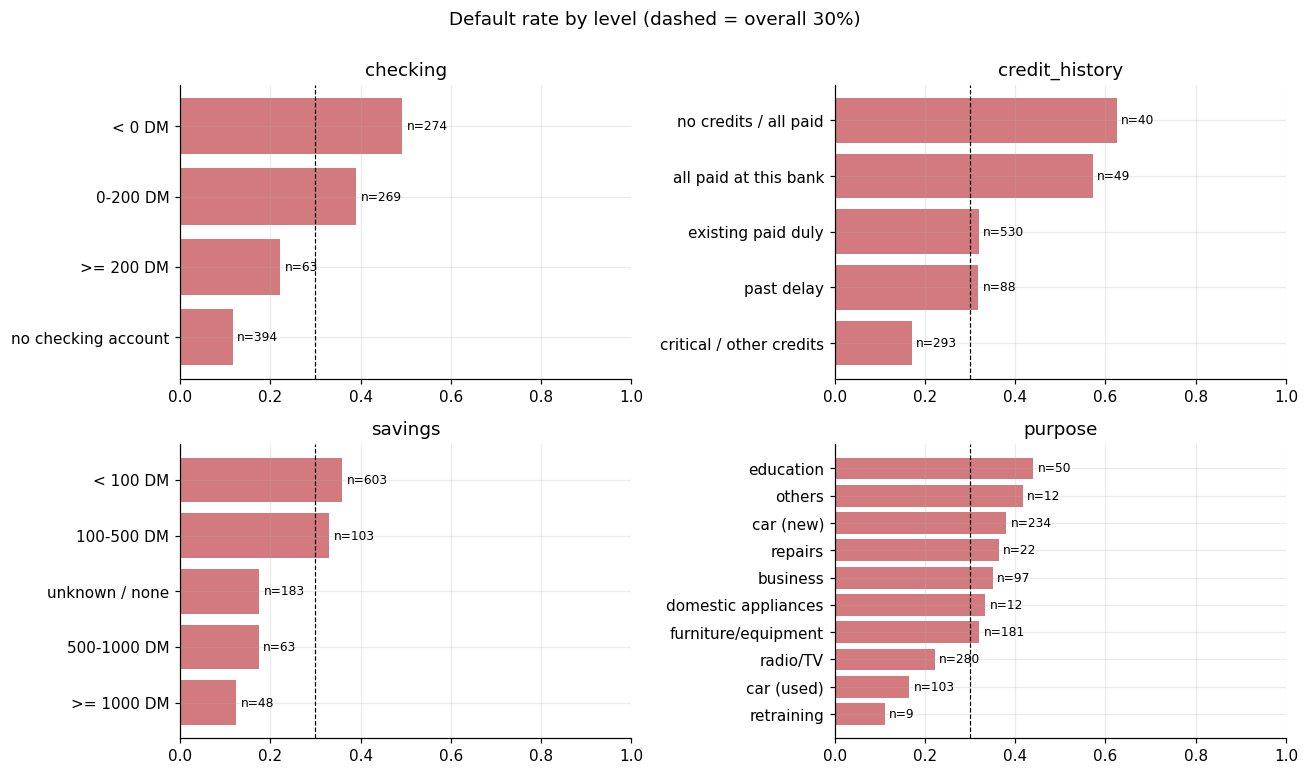

In [ ]:
top = ["checking", "credit_history", "savings", "purpose"]
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for a, f in zip(ax.ravel(), top):
    g = df.groupby(f)["default"].agg(["mean", "size"]).sort_values("mean")
    a.barh(g.index, g["mean"], color=C_BAD, alpha=.75)
    for y, (m, n) in enumerate(zip(g["mean"], g["size"])): a.text(m + .01, y, f"n={n}", va="center", fontsize=8)
    a.axvline(df["default"].mean(), ls="--", c="k", lw=.8)
    a.set_title(f); a.set_xlim(0, 1)
fig.suptitle("Default rate by level (dashed = overall 30%)", y=1.0)
plt.tight_layout(); plt.show()

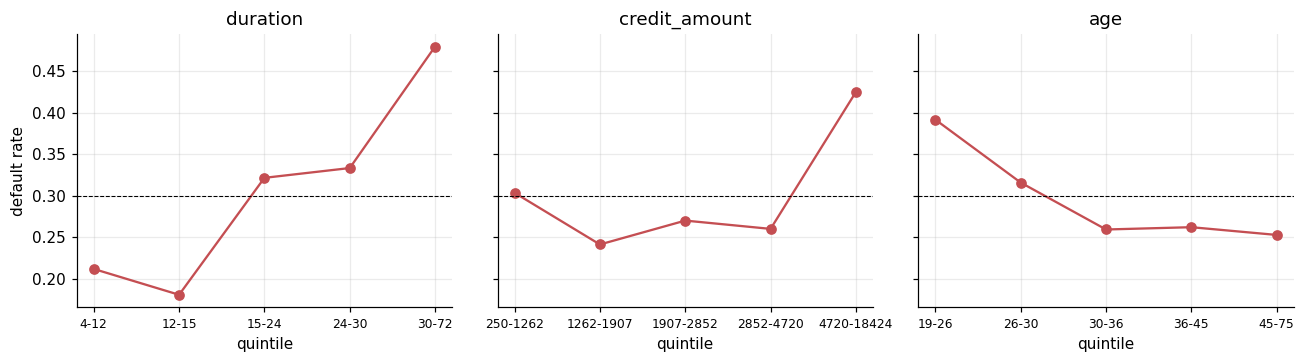

In [ ]:
# Default rate across quintiles of each continuous variable: checks linearity of the effect
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for a, c in zip(ax, NUM_CONT):
    g = df.groupby(pd.qcut(df[c], 5, duplicates="drop"), observed=True)["default"].mean()
    a.plot(range(len(g)), g.values, marker="o", color=C_BAD)
    a.set_xticks(range(len(g)), [f"{iv.left:.0f}-{iv.right:.0f}" for iv in g.index], fontsize=8)
    a.axhline(df["default"].mean(), ls="--", c="k", lw=.7); a.set_title(c); a.set_xlabel("quintile")
ax[0].set_ylabel("default rate")
plt.tight_layout(); plt.show()

In [ ]:
# default rate by quintile (backs the quintile figures in the text)
for c in NUM_CONT:
    print(c)
    print(df.groupby(pd.qcut(df[c], 5, duplicates="drop"), observed=True)["default"]
            .agg(n="size", default_rate="mean").round(3), "\n")

duration
                 n  default_rate
duration                        
(3.999, 12.0]  359         0.212
(12.0, 15.0]    72         0.181
(15.0, 24.0]   339         0.322
(24.0, 30.0]    57         0.333
(30.0, 72.0]   173         0.480 

credit_amount
                     n  default_rate
credit_amount                       
(249.999, 1262.0]  201         0.303
(1262.0, 1906.8]   199         0.241
(1906.8, 2852.4]   200         0.270
(2852.4, 4720.0]   200         0.260
(4720.0, 18424.0]  200         0.425 

age
                  n  default_rate
age                              
(18.999, 26.0]  240         0.392
(26.0, 30.0]    171         0.316
(30.0, 36.0]    216         0.259
(36.0, 45.0]    187         0.262
(45.0, 75.0]    186         0.253 



In [ ]:
# default rate for short vs long loans and young vs older applicants
cuts = {"duration <= 15": df["duration"] <= 15, "duration > 30": df["duration"] > 30,
        "age <= 26": df["age"] <= 26, "age > 30": df["age"] > 30}
pd.DataFrame([{"group": k, "n": int(m.sum()), "default_rate": round(df.loc[m, "default"].mean(), 3)}
              for k, m in cuts.items()])

,group,n,default_rate
0,duration <= 15,431,0.206
1,duration > 30,173,0.480
2,age <= 26,240,0.392
3,age > 30,589,0.258


In [ ]:
# Table 3.4 for the report
def row(var, group, mask):
    return (var, group, int(mask.sum()), f"{df.loc[mask, 'default'].mean():.1%}")

rows = [row("checking", lv, df["checking"] == lv)
        for lv in ["< 0 DM", "0-200 DM", ">= 200 DM", "no checking account"]]
rows += [row("credit_history", lv, df["credit_history"] == lv)
         for lv in ["critical / other credits", "existing paid duly", "no credits / all paid"]]
rows += [row("duration", "up to 15 months", df["duration"] <= 15),
         row("duration", "over 30 months", df["duration"] > 30)]
q = pd.qcut(df["credit_amount"], 5, labels=["smallest", "2nd", "3rd", "4th", "largest"])
rows += [row("credit_amount (quintile)", lv, q == lv) for lv in q.cat.categories]
rows += [row("age", "26 or under", df["age"] <= 26), row("age", "over 30", df["age"] > 30)]

pd.DataFrame(rows, columns=["variable", "group", "n", "default rate"]).set_index(["variable", "group"])

n default rate
variable                 group                                     
checking                 < 0 DM                    274        49.3%
                         0-200 DM                  269        39.0%
                         >= 200 DM                  63        22.2%
                         no checking account       394        11.7%
credit_history           critical / other credits  293        17.1%
                         existing paid duly        530        31.9%
                         no credits / all paid      40        62.5%
duration                 up to 15 months           431        20.6%
                         over 30 months            173        48.0%
credit_amount (quintile) smallest                  201        30.3%
                         2nd                       199        24.1%
                         3rd                       200        27.0%
                         4th                       200        26.0%
                         largest                   200        42.5%
age                      26 or under               240        39.2%
                         over 30                   589        25.8%

In [ ]:
# Table 3.4 for the report
def row(var, group, mask):
    return (var, group, int(mask.sum()), f"{df.loc[mask, 'default'].mean():.1%}")

rows = [row("checking", lv, df["checking"] == lv)
        for lv in ["< 0 DM", "0-200 DM", ">= 200 DM", "no checking account"]]
rows += [row("credit_history", lv, df["credit_history"] == lv)
         for lv in ["critical / other credits", "existing paid duly", "no credits / all paid"]]
rows += [row("duration", "up to 15 months", df["duration"] <= 15),
         row("duration", "over 30 months", df["duration"] > 30)]
q = pd.qcut(df["credit_amount"], 5, labels=["smallest", "2nd", "3rd", "4th", "largest"])
rows += [row("credit_amount (quintile)", lv, q == lv) for lv in q.cat.categories]
rows += [row("age", "26 or under", df["age"] <= 26), row("age", "over 30", df["age"] > 30)]

pd.DataFrame(rows, columns=["variable", "group", "n", "default rate"]).set_index(["variable", "group"])

n default rate
variable                 group                                     
checking                 < 0 DM                    274        49.3%
                         0-200 DM                  269        39.0%
                         >= 200 DM                  63        22.2%
                         no checking account       394        11.7%
credit_history           critical / other credits  293        17.1%
                         existing paid duly        530        31.9%
                         no credits / all paid      40        62.5%
duration                 up to 15 months           431        20.6%
                         over 30 months            173        48.0%
credit_amount (quintile) smallest                  201        30.3%
                         2nd                       199        24.1%
                         3rd                       200        27.0%
                         4th                       200        26.0%
                         largest                   200        42.5%
age                      26 or under               240        39.2%
                         over 30                   589        25.8%

In [25]:
# full table of default rate by level for every categorical variable
pd.concat({c: df.groupby(c)["default"].agg(n="size", default_rate="mean")
                  .sort_values("default_rate", ascending=False) for c in CAT},
          names=["feature", "level"]).round(3)

n  default_rate
feature             level                                                 
checking            < 0 DM                               274         0.493
                    0-200 DM                             269         0.390
                    >= 200 DM                             63         0.222
                    no checking account                  394         0.117
credit_history      no credits / all paid                 40         0.625
                    all paid at this bank                 49         0.571
                    existing paid duly                   530         0.319
                    past delay                            88         0.318
                    critical / other credits             293         0.171
purpose             education                             50         0.440
                    others                                12         0.417
                    car (new)                            234         0.380
                    repairs                               22         0.364
                    business                              97         0.351
                    domestic appliances                   12         0.333
                    furniture/equipment                  181         0.320
                    radio/TV                             280         0.221
                    car (used)                           103         0.165
                    retraining                             9         0.111
savings             < 100 DM                             603         0.360
                    100-500 DM                           103         0.330
                    unknown / none                       183         0.175
                    500-1000 DM                           63         0.175
                    >= 1000 DM                            48         0.125
employment          < 1 yr                               172         0.407
                    unemployed                            62         0.371
                    1-4 yrs                              339         0.307
                    >= 7 yrs                             253         0.253
                    4-7 yrs                              174         0.224
personal_status_sex male: divorced/separated              50         0.400
                    female: div/sep/married              310         0.352
                    male: married/widowed                 92         0.272
                    male: single                         548         0.266
other_debtors       co-applicant                          41         0.439
                    none                                 907         0.300
                    guarantor                             52         0.192
property            unknown / none                       154         0.435
                    car or other                         332         0.307
                    savings agmt / life insurance        232         0.306
                    real estate                          282         0.213
other_installment   bank                                 139         0.410
                    stores                                47         0.404
                    none                                 814         0.275
housing             for free                             108         0.407
                    rent                                 179         0.391
                    own                                  713         0.261
job                 management / highly qualified        148         0.345
                    unemployed / unskilled non-resident   22         0.318
                    skilled                              630         0.295
                    unskilled resident                   200         0.280
telephone           none                                 596         0.314
                    yes                                  404         0.280
foreign_w

- Checking account has the clearest pattern. The default rate goes from 49.3% (< 0 DM) to 39.0% (0-200 DM), 22.2% (>= 200 DM) and 11.7% (no account). Savings go the same way, from 36.0% (< 100 DM) to 12.5% (>= 1000 DM).
- Credit history looks backwards at first. "Critical account / other credits" defaults at 17.1%, lower than "existing credits paid duly" (31.9%). The highest rate is for "no credits / all paid" (62.5%), but that group has only 40 applicants. This is counterintuitive, so it is worth checking again when we interpret the models in part (e).
- Several effects are not linear. Loans of up to 15 months default at 20.6% and loans over 30 months at 48.0%. Credit amount is U-shaped: 30.3% for the smallest quintile, 24.1 to 27.0% in the middle three and 42.5% for the largest. Applicants aged 26 or under default at 39.2%, against 25.8% for those over 30. A linear term will miss the credit amount shape, so part (b) could try bins or squared terms for logistic regression. Trees handle it already.
- Defaulters have a longer median duration (24 vs 18 months), a slightly higher median amount (2,575 vs 2,244 DM) and are younger (31 vs 34).
- The duration quintiles are very uneven in size (72 and 57 loans in two of them) because many loans have the same duration (12, 24, 36 months), so we use cut-offs for duration in the text.

### Correlations

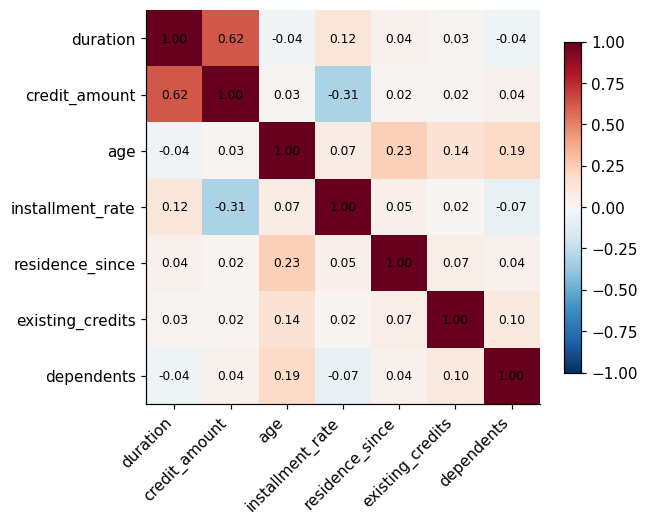

In [ ]:
num_all = NUM_CONT + NUM_DISC
corr = df[num_all].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(num_all)), num_all, rotation=45, ha="right"); ax.set_yticks(range(len(num_all)), num_all)
for i in range(len(num_all)):
    for j in range(len(num_all)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, shrink=.8); plt.tight_layout(); plt.show()

`duration` and `credit_amount` are strongly correlated (0.62) and `installment_rate` and `credit_amount` moderately negatively (-0.31). Everything else is weak (absolute value at most 0.23). Because of the first pair, their logistic regression coefficients should be read together. It also suggests `credit_amount / duration` (roughly the monthly payment) as a feature for part (b).

## 8. Save cleaned data

In [ ]:
for c in NUM_CONT:
    df[f"log_{c}"] = np.log1p(df[c])

assert df.shape[0] == 1000 and df.isna().sum().sum() == 0
from pathlib import Path
Path(OUT).parent.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT, index=False)

chk = pd.read_csv(OUT)
print("Saved:", OUT, chk.shape)
print("Columns:", chk.columns.tolist())

Saved: data/processed/german_clean.csv (1000, 25)
Columns: ['checking', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings', 'employment', 'installment_rate', 'personal_status_sex', 'other_debtors', 'residence_since', 'property', 'age', 'other_installment', 'housing', 'existing_credits', 'job', 'dependents', 'telephone', 'foreign_worker', 'default', 'sex', 'log_duration', 'log_credit_amount', 'log_age']


## Summary

| Issue | What we found | What we did |
|---|---|---|
| Missing values | None, but 3 "no account / unknown" categories | Kept as their own categories |
| Duplicates, invalid codes, ranges | None | - |
| Contradictions | 3 applicants aged 20 with 7+ years employment; 33 "unemployed" applicants with job code A174 (management / self-employed) | Kept (0.3% and 3.3% of rows; the second is most likely self-employed) |
| Skew | credit_amount 1.95, duration 1.09, age 1.02 | Added log columns, kept originals |
| Outliers | 70 (duration), 72 (amount), 23 (age) by IQR | Kept; they are real and informative |
| Target | 70% good, 30% bad; cost 5:1 | `default = 1` for bad; cutoff about 1/6 |

# Part (b): Feature Engineering
We build on the cleaned `df` from part (a). The brief asks for loan-to-income, debt-to-income and employment categories. The data has **no income or total-debt column**, so the first two are built as proxies from what `german.doc` does give us. The steps are:

- Section 9: affordability proxies (monthly payment, debt-to-income, income index, loan-to-income, total debt-to-income) and their logs.
- Section 10: employment categories, splitting "unemployed" into self-employed and unemployed, plus an ordinal tenure score.
- Section 11: merge the rare `purpose` levels flagged in section 6, and add age bands for the non-linear age effect seen in section 7.
- Section 12: one stratified train/test split for all later parts, and credit-amount bins for the U-shape seen in section 7.
- Section 13: save everything as `data/processed/german_clean_modified.csv`.

The only step that learns from the data (the credit-amount quantile edges) is fitted on the training split only. The other features are fixed formulas or domain-based groupings, so building them on the full data does not leak test information.

In [ ]:
from sklearn.model_selection import train_test_split
fe = df.copy()

## 9. Affordability: debt-to-income and loan-to-income
`installment_rate` is defined as "instalment rate in percentage of disposable income", so it is already a **debt-to-income ratio for this loan** .
- monthly payment ≈ `credit_amount / duration`
- disposable monthly income ∝ payment / rate, so `income_index = monthly_payment / installment_rate`
- **loan-to-income** = `credit_amount / income_index = duration × installment_rate`, i.e. how many months of (scaled) income the loan is worth
- **total debt-to-income** ≈ `installment_rate × existing_credits`, assuming the applicant's other credits at the bank cost about as much as this one. `other_installments` flags instalment plans at other banks or stores.

The rate is a 1-4 code, not an exact percentage, so `income_index` and `lti` are only correct up to a constant and are coarse.

In [ ]:
fe["monthly_payment"] = fe["credit_amount"] / fe["duration"]          # flat instalment, no interest
fe["dti"] = fe["installment_rate"]                                    # this loan's instalment / disposable income (1-4)
fe["income_index"] = fe["monthly_payment"] / fe["installment_rate"]   # proportional to monthly disposable income
fe["lti"] = fe["credit_amount"] / fe["income_index"]                  # loan / monthly income, = duration * rate
fe["total_dti"] = fe["installment_rate"] * fe["existing_credits"]     # burden if other credits look like this one
fe["other_installments"] = (fe["other_installment"] != "none").astype(int)
assert np.allclose(fe["lti"], fe["duration"] * fe["installment_rate"])

for c in ["monthly_payment", "income_index", "lti"]:
    fe[f"log_{c}"] = np.log1p(fe[c])

NEW_NUM = ["monthly_payment", "income_index", "lti", "total_dti"]
fe[NEW_NUM].describe().T.assign(skew=fe[NEW_NUM].skew()).round(2)

,count,mean,std,min,25%,50%,75%,max,skew
monthly_payment,1000.0,167.69,153.49,24.06,89.6,130.33,206.18,2482.67,7.63
income_index,1000.0,86.16,148.89,6.31,25.0,44.03,93.83,2482.67,9.33
lti,1000.0,63.15,44.37,4.00,30.0,48.00,96.00,240.00,1.17
total_dti,1000.0,4.20,2.44,1.00,2.0,4.00,4.00,16.00,1.21


`monthly_payment` and `income_index` are very skewed (skew 7.6 and 9.3), so we add `log_` versions for linear models. `lti` and `total_dti` are moderately skewed (about 1.2) and bounded.

## 10. Employment categories
`employment` (A71-A75) measures time with the current *employer*. Section 2 found 33 of the 62 A71 "unemployed" applicants have job code A174 ("management / self-employed / highly qualified"), so these are most likely self-employed rather than out of work. We combine the two columns into:

- `emp_category`: self-employed (employment A71 with job A174), unemployed (the other 29 A71 applicants), short (< 1 yr), medium (1-4 yrs), long (4-7 yrs), very long (>= 7 yrs).
- `emp_years`: tenure as an ordinal 0-4, for models that can use the numerical ordering.

In [ ]:
EMP_YEARS = {"unemployed": 0, "< 1 yr": 1, "1-4 yrs": 2, "4-7 yrs": 3, ">= 7 yrs": 4}
fe["emp_years"] = fe["employment"].map(EMP_YEARS)

self_emp = (fe["employment"] == "unemployed") & (fe["job"] == "management / highly qualified")
fe["emp_category"] = np.select(
    [self_emp, fe["employment"] == "unemployed", fe["employment"] == "< 1 yr",
     fe["employment"] == "1-4 yrs", fe["employment"] == "4-7 yrs"],
    ["self-employed", "unemployed", "short (< 1 yr)", "medium (1-4 yrs)", "long (4-7 yrs)"],
    default="very long (>= 7 yrs)")

EMP_ORDER = ["self-employed", "unemployed", "short (< 1 yr)", "medium (1-4 yrs)", "long (4-7 yrs)", "very long (>= 7 yrs)"]
fe.groupby("emp_category").agg(emp_years=("emp_years", "first"), n=("emp_years", "size")).reindex(EMP_ORDER)

,emp_years,n
emp_category,,
self-employed,0,33
unemployed,0,29
short (< 1 yr),1,172
medium (1-4 yrs),2,339
long (4-7 yrs),3,174
very long (>= 7 yrs),4,253


## 11. Rare levels and fixed bins
- `purpose_grp`: retraining (9) joins education (50), since both are spending on skills; domestic appliances (12), repairs (22) and others (12) become "other" (46). Every level now has at least 46 rows. **Why:** default rates on 9-22 rows are noise (one extra default moves the rate by up to 11 points), and such levels can be missing from some CV folds, giving unstable or unseen one-hot columns.
- `age_group`: < 25, 25-34, 35-49, 50+. **Why:** section 7 showed default dropping steeply until about 30 and then flattening, which a single linear age term in logistic regression cannot fit; bands give each age range its own coefficient. Trees find this shape themselves, so the bands are mainly for logistic regression.

Both are fixed rules (domain grouping and round cut points chosen in advance), not fitted to the data, so applying them before the split does not leak test information.

In [ ]:
PURPOSE_GRP = {"retraining": "education / retraining", "education": "education / retraining",
               "domestic appliances": "other", "repairs": "other", "others": "other"}
fe["purpose_grp"] = fe["purpose"].replace(PURPOSE_GRP)

fe["age_group"] = pd.cut(fe["age"], [0, 25, 35, 50, np.inf], right=False,
                         labels=["< 25", "25-34", "35-49", "50+"]).astype(str)

for c in ["purpose_grp", "age_group"]:
    print(fe[c].value_counts().to_dict())

{'radio/TV': 280, 'car (new)': 234, 'furniture/equipment': 181, 'car (used)': 103, 'business': 97, 'education / retraining': 59, 'other': 46}
{'25-34': 399, '35-49': 327, '< 25': 149, '50+': 125}


## 12. Train/test split
A stratified 80/20 split with `random_state=42`, stored as a `split` column so parts (c)-(e) all use the same test set. Both halves have exactly 30% defaults.

The U-shape of `credit_amount` (section 7) is handled by `amount_bin`, quintiles of credit amount. The edges are fitted on the training rows only, and the outer bins are left open so test values outside the training range still get a bin.

In [ ]:
train_idx, test_idx = train_test_split(fe.index, test_size=0.2, stratify=fe["default"], random_state=42)
fe["split"] = "train"
fe.loc[test_idx, "split"] = "test"
print(fe.groupby("split")["default"].agg(n="size", default_rate="mean").round(3))

# amount bins: quintile edges from the train split only
_, edges = pd.qcut(fe.loc[train_idx, "credit_amount"], 5, retbins=True)
edges[0], edges[-1] = -np.inf, np.inf
fe["amount_bin"] = pd.cut(fe["credit_amount"], edges, labels=[f"Q{i}" for i in range(1, 6)]).astype(str)
print("amount bin edges (train):", np.round(edges[1:-1]).tolist())

         n  default_rate
split                   
test   200           0.3
train  800           0.3
amount bin edges (train): [1256.0, 1891.0, 2815.0, 4630.0]


## 13. Save

In [ ]:
OUT_MOD = "data/processed/german_clean_modified.csv"
assert fe.shape[0] == 1000 and fe.notna().all().all()
fe.to_csv(OUT_MOD, index=False)

print("Saved:", OUT_MOD, fe.shape)
print("Columns added to german_clean:", [c for c in fe.columns if c not in df.columns])

Saved: data/processed/german_clean_modified.csv (1000, 40)
Columns added to german_clean: ['monthly_payment', 'dti', 'income_index', 'lti', 'total_dti', 'other_installments', 'log_monthly_payment', 'log_income_index', 'log_lti', 'emp_years', 'emp_category', 'purpose_grp', 'age_group', 'split', 'amount_bin']


## Summary of part (b)

| Column | Definition | Purpose |
|---|---|---|
| `monthly_payment` | `credit_amount / duration` | size of the repayment |
| `dti` (= `installment_rate`) | instalment as % of disposable income, 1-4 code | debt-to-income for this loan |
| `income_index` | `monthly_payment / installment_rate` | relative disposable income |
| `lti` | `credit_amount / income_index` = `duration × installment_rate` | loan-to-income proxy |
| `total_dti` | `installment_rate × existing_credits` | total debt burden proxy |
| `other_installments` | 1 if instalment plans at other banks / stores | debt outside this bank |
| `log_monthly_payment`, `log_income_index`, `log_lti` | `log1p` of `monthly_payment`, `income_index`, `lti` | reduce skew for linear models |
| `emp_years` | employment tenure as ordinal 0-4 | ordered version of `employment` |
| `emp_category` | self-employed / unemployed / < 1 / 1-4 / 4-7 / >= 7 yrs | employment categories |
| `purpose_grp` | rare purposes merged (all levels n >= 46) | stable estimates in CV folds |
| `age_group` | < 25, 25-34, 35-49, 50+ (fixed cut points) | non-linear age effect |
| `split` | stratified 80/20 train / test, `random_state=42` | same test set for parts (c)-(e) |
| `amount_bin` | credit-amount quintiles, edges from train split | U-shaped amount effect |

All 15 columns are added to the part (a) data; no original column is changed or dropped.

Notes for the other parts:
- Load `data/processed/german_clean_modified.csv`, train on `split == "train"` and use `split == "test"` only for the final evaluation.
- LTI, DTI and the income index are relative rankings built from a 1-4 code, not amounts in DM.
- In logs, `log_monthly_payment` ≈ `log_credit_amount - log_duration` and `lti` = `duration × installment_rate`, so logistic regression should not use the ratios alongside the raw amount, duration and rate. Tree models can use them.

# Part (c): Models

## (i) Logistic Regression

Logistic regression models the **log-odds of default** as a weighted sum of the features: each coefficient says how much one unit of a feature raises or lowers the odds of default, holding the others fixed. It is the standard credit-scoring model because the output is a real probability and every coefficient can be read and checked.

All variables in this section end in `_lr` (e.g. `x_train_lr`) so they don't overwrite the random forest and AdaBoost variables.

### 1) Imports

In [28]:
# numpy, pandas and matplotlib are already imported in part (a)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score

### 2) Load data and basic model
We load the part (b) file and use its `split` column, so the model is trained on the same 800 applicants and tested on the same 200 as the other models. This step only sets up the candidate variables. Variable selection is done in 2.3 and tuning in step 3, both on the **training rows only**.

#### 2.1) Load the data and choose the candidates
**Candidates:** 
- `log_duration` and `log_credit_amount` are used because the distribution of the raw variables are skewed
- `age_group` is used because a non-linear age effect has been observed from the EDA. Using the variable `age` instead may not capture this effect.
- Original categorical columns

**Left out:** 
- ratios in part (b) (`monthly_payment`, `income_index`, `lti`, `dti`, `total_dti` and their logs). They are redundant with `duration`, `credit_amount`, `installment_rate` and `existing_credits`: `lti` and `total_dti` are products of those columns, and the log versions are close to linear combinations of their logs.
- `purpose`, `employment`, `emp_years`, `other_installments` and `sex`, which `purpose_grp`, `emp_category`, `other_installment` and `personal_status_sex` replace. `sex` is derived from `personal_status_sex`, which stays a candidate
- `amount_bin` since `log_credit_amount` already tests whether loan size matters

In [29]:
# Load the cleaned from part (b)
data_lr = pd.read_csv("data/processed/german_clean_modified.csv")

# CANDIDATE variables 
candidate_num_lr = ["log_duration", "log_credit_amount", "installment_rate",
                    "residence_since", "existing_credits", "dependents"]
candidate_cat_lr = ["checking", "credit_history", "purpose_grp", "savings", "emp_category",
                    "personal_status_sex", "other_debtors", "property", "other_installment",
                    "housing", "job", "telephone", "foreign_worker", "age_group"]

# Define target column (1 = bad / default, 0 = good)
target = "default"

# Use the train/test split from part (b)
is_train = data_lr["split"] == "train"

#### 2.2) Basic logistic regression model
Fit the most basic logistic regression model using **all** candidate variables, and score it with 5-fold cross-validated AUC on the **training rows only**. 

In [30]:
X_cand = pd.get_dummies(data_lr[candidate_num_lr + candidate_cat_lr], columns=candidate_cat_lr, dtype=int)
y_lr = data_lr[target]

x_train_cand, y_train_lr = X_cand[is_train], y_lr[is_train]

# The same 5 folds are used in every step below
cv_lr = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

basic_model = LogisticRegression(max_iter=10_000)
basic_auc = cross_val_score(basic_model, x_train_cand, y_train_lr, cv=cv_lr, scoring="roc_auc").mean()

print(f"Basic model (all variables) CV AUC: {basic_auc:.4f}")

Basic model (all variables) CV AUC: 0.7715


With all 20 candidate groups (62 columns) the basic model has a CV AUC of **0.7715**. This is used as a reference.

#### 2.3) Backward elimination
Each candidate variable is one group, so all dummy columns of a categorical variable are removed together. Start with all 20 groups and drop the one whose removal gives the highest CV AUC. **Stop** when every possible removal would lower the CV AUC.

In [31]:
groups = candidate_num_lr + candidate_cat_lr
current = groups.copy()

def get_auc(variables):
    cols = []
    for var in variables:
        cols.extend(
            [c for c in X_cand.columns
             if c == var or c.startswith(var + "_")]
        )

    model = LogisticRegression(max_iter=10_000)

    return cross_val_score(
        model, x_train_cand[cols], y_train_lr,
        cv=cv_lr, scoring="roc_auc"
    ).mean()

best_auc = get_auc(current)
print("All 20 groups | AUC:", round(best_auc, 4))
while len(current) > 1:
    results = {}

    for var in current:
        remaining = [v for v in current if v != var]
        results[var] = get_auc(remaining)
    remove = max(results, key=results.get)
    if results[remove] < best_auc:
        break

    current.remove(remove)
    best_auc = results[remove]

    print("Removed:", remove, "| AUC:", round(best_auc, 4))

selected_groups_basic = current
dropped_groups_basic = [v for v in groups if v not in current]

print("Selected:", selected_groups_basic)
print("Dropped:", dropped_groups_basic)

All 20 groups | AUC: 0.7715


Removed: other_debtors | AUC: 0.7752


Removed: job | AUC: 0.7781


Removed: existing_credits | AUC: 0.7805


Removed: residence_since | AUC: 0.7805


Selected: ['log_duration', 'log_credit_amount', 'installment_rate', 'dependents', 'checking', 'credit_history', 'purpose_grp', 'savings', 'emp_category', 'personal_status_sex', 'property', 'other_installment', 'housing', 'telephone', 'foreign_worker', 'age_group']
Dropped: ['residence_since', 'existing_credits', 'other_debtors', 'job']


Backward elimination removes 4 of the 20 groups: `other_debtors`, `job`, `existing_credits` and `residence_since`, in that order. The CV AUC rises from 0.7715 to 0.7805, so we stop and keep **16 groups**.

### 3) Tuning
We tune `C` (the strength of the L2 penalty) with 5-fold CV AUC on the **training rows only**.

In [32]:
# Keep only the variables selected in 2.3
num_features_lr = [v for v in candidate_num_lr if v in selected_groups_basic]
cat_features_lr = [v for v in candidate_cat_lr if v in selected_groups_basic]

X_lr = pd.get_dummies(data_lr[num_features_lr + cat_features_lr], columns=cat_features_lr, dtype=int)
x_train_lr, x_test_lr = X_lr[is_train], X_lr[~is_train]
y_test_lr = y_lr[~is_train]

# Tune C
lr_grid = GridSearchCV(LogisticRegression(max_iter=10_000), {"C": np.logspace(-3, 2, 11)},
                       scoring="roc_auc", cv=cv_lr)
lr_grid.fit(x_train_lr, y_train_lr)

lr_best = lr_grid.best_estimator_     
feat_names_lr = list(x_train_lr.columns)

print(f"Best C: {lr_grid.best_params_['C']:.4f}   CV AUC: {lr_grid.best_score_:.4f}")

Best C: 0.0316   CV AUC: 0.7850


In [ ]:
# CV cost per applicant on the training set only: out-of-fold P(default), flag high risk if > 1/6,
# cost per applicant = (5*FN + 1*FP) / n   (FN = defaulter approved, FP = good borrower rejected)
from sklearn.model_selection import cross_val_predict

cutoff_lr = 1 / 6      # same cost-optimal cutoff as in section 4

stages_lr = {
    "2.2 Basic model, all 20 variable groups":   (LogisticRegression(max_iter=10_000), x_train_cand),
    "2.3 After backward elimination, 16 groups": (LogisticRegression(max_iter=10_000), x_train_lr),
    f"3 After tuning C (C = {lr_best.C:.4f})":    (lr_best, x_train_lr),
}

rows = []
for stage, (model, X) in stages_lr.items():
    fold_auc = cross_val_score(model, X, y_train_lr, cv=cv_lr, scoring="roc_auc")
    p_oof = cross_val_predict(model, X, y_train_lr, cv=cv_lr, method="predict_proba")[:, 1]
    high_risk = p_oof > cutoff_lr
    fn = int((~high_risk & (y_train_lr.values == 1)).sum())
    fp = int((high_risk & (y_train_lr.values == 0)).sum())
    rows.append((stage, round(fold_auc.mean(), 4), round(fold_auc.std(), 4), round((5 * fn + fp) / len(y_train_lr), 3)))

print(pd.DataFrame(rows, columns=["Stage", "CV AUC", "AUC SD", "CV cost per applicant"]).to_string(index=False))

                                    Stage  CV AUC  AUC SD  CV cost per applicant
  2.2 Basic model, all 20 variable groups  0.7715  0.0389                  0.554
2.3 After backward elimination, 16 groups  0.7805  0.0403                  0.529
            3 After tuning C (C = 0.0316)  0.7850  0.0442                  0.529


The best `C` is **0.0316**

| Stage | CV AUC | AUC SD | CV cost per applicant |
|---|---|---|---|
| 2.2 Basic model, all 20 variable groups | 0.7715 | 0.0389 | 0.554 |
| 2.3 After backward elimination, 16 groups | 0.7805 | 0.0403 | 0.529 |
| 3 After tuning `C` | 0.7850 | 0.0442 | 0.529 |

AUC SD is the standard deviation of the AUC across the 5 folds. CV cost per applicant is the out-of-fold cost at the 1/6 cutoff, (5 × FN + FP) / n, on the training set.

### 4) Testing

ROC-AUC:   0.7825 
Accuracy:  0.4650
Precision: 0.3503 
Recall:    0.9167 


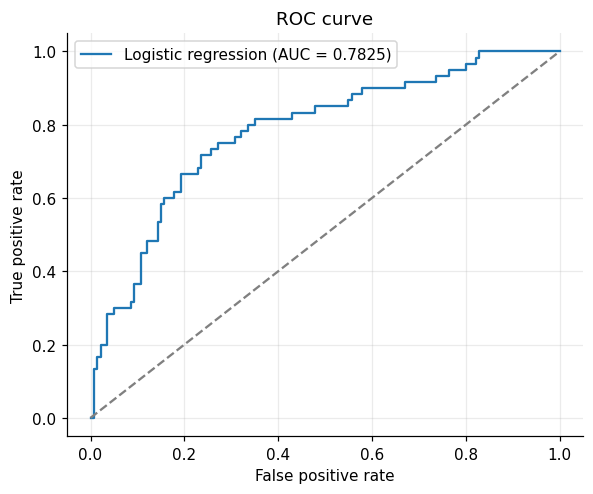

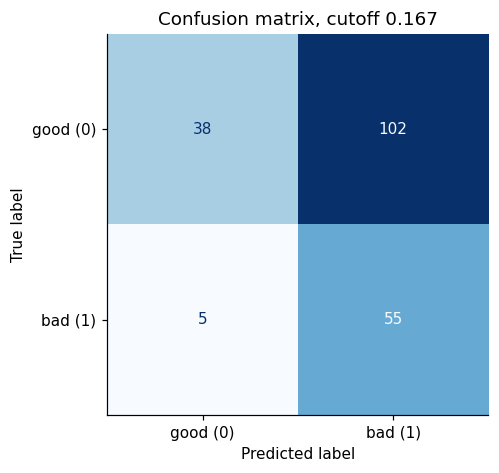

In [33]:
# Flag an applicant as bad (1) when P(default) > 1/6, since approving a defaulter costs 5x more than rejecting a good applicant
THRESHOLD = 1 / 6
y_proba_lr = lr_best.predict_proba(x_test_lr)[:, 1]
y_pred_lr = (y_proba_lr > THRESHOLD).astype(int)

print(f"ROC-AUC:   {roc_auc_score(y_test_lr, y_proba_lr):.4f} ")
print(f"Accuracy:  {accuracy_score(y_test_lr, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test_lr, y_pred_lr):.4f} ")
print(f"Recall:    {recall_score(y_test_lr, y_pred_lr):.4f} ")

# ROC curve (own figure)
fpr, tpr, thr = roc_curve(y_test_lr, y_proba_lr)
i_cut = np.argmin(np.abs(thr - THRESHOLD))
plt.figure(figsize=(5.5, 4.6))
plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {roc_auc_score(y_test_lr, y_proba_lr):.4f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curve"); plt.legend()
plt.tight_layout(); plt.show()

# Confusion matrix (own figure): rows = actual (0 good, 1 bad), columns = predicted
fig, ax = plt.subplots(figsize=(5, 4.4))
ConfusionMatrixDisplay(confusion_matrix(y_test_lr, y_pred_lr), display_labels=["good (0)", "bad (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.grid(False); ax.set_title(f"Confusion matrix, cutoff {THRESHOLD:.3f}")
plt.tight_layout(); plt.show()

On the 200 test applicants, the ROC-AUC is **0.7825**, close to the cross-validated 0.785, so there is no sign of overfitting. At the 1/6 cutoff the model catches 55 of the 60 bad borrowers (recall 0.92) and misses 5, but it also rejects 102 of the 140 good ones (precision 0.35, accuracy 0.47). Low accuracy and precision are expected here, because the cutoff is set to avoid approving defaulters, which costs 5 times more than rejecting a good applicant.

In [34]:
# Misclassification cost
def cost_per_applicant(y_true, y_pred):
    """Average cost: 5 per bad borrower approved (FN) + 1 per good borrower rejected (FP)."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return (5 * fn + 1 * fp) / len(y_true)

n_test = len(y_test_lr)
cost_table_lr = pd.Series({
    "Logistic regression, cutoff 1/6": cost_per_applicant(y_test_lr, y_pred_lr),
    "Logistic regression, cutoff 0.5": cost_per_applicant(y_test_lr, (y_proba_lr > 0.5).astype(int)),
    "Approve everyone":                cost_per_applicant(y_test_lr, np.zeros(n_test, dtype=int)),
    "Reject everyone":                 cost_per_applicant(y_test_lr, np.ones(n_test, dtype=int)),
}, name="cost per applicant").round(3)
cost_table_lr

Logistic regression, cutoff 1/6    0.635
Logistic regression, cutoff 0.5    1.100
Approve everyone                   1.500
Reject everyone                    0.700
Name: cost per applicant, dtype: float64

### 5) SHAP Analysis - Logistic Regression

In [35]:
import shap
masker_lr = shap.maskers.Independent(x_train_lr, max_samples=len(x_train_lr))
explainer_lr = shap.LinearExplainer(lr_best, masker_lr)
sv_lr = explainer_lr(x_test_lr)

#### 5.1) Global view: beeswarm plot
The plot shows the 15 most influential features and groups the rest in the last row.

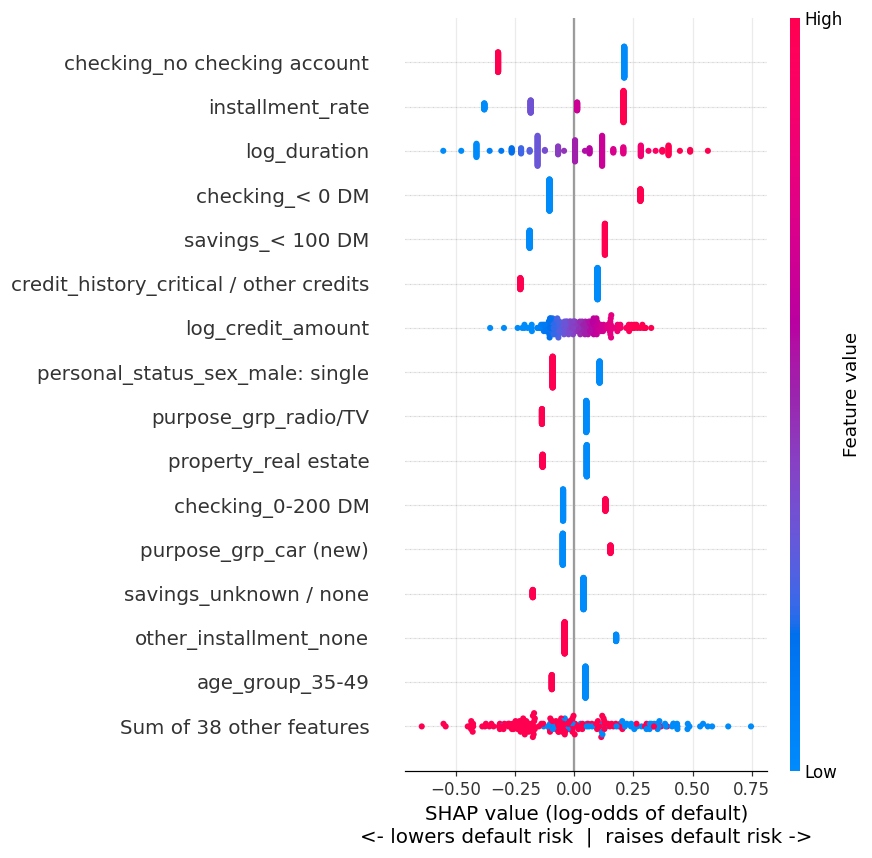

In [36]:
shap.plots.beeswarm(sv_lr, max_display=16, show=False)
plt.xlabel("SHAP value (log-odds of default)\n<- lowers default risk  |  raises default risk ->")
plt.tight_layout(); plt.show()

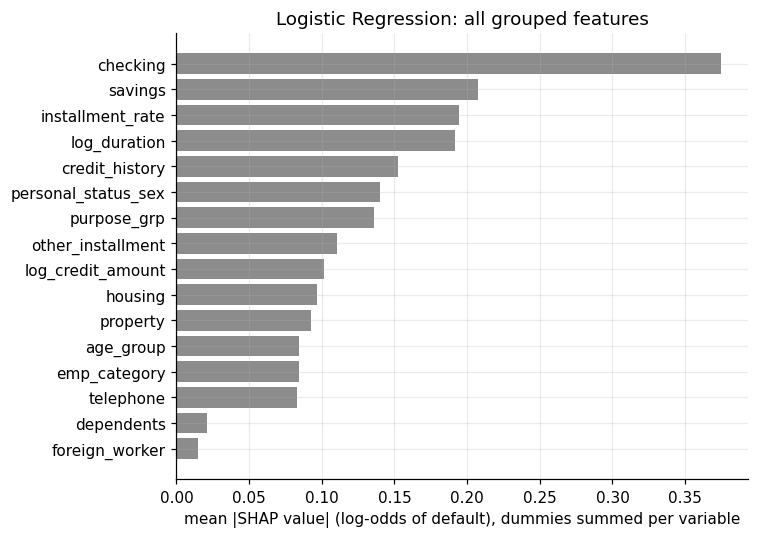

In [37]:
# Map every column to its original variable (same rule as the backward elimination: exact name or name_level)
group_of_lr = {c: next(v for v in num_features_lr + cat_features_lr if c == v or c.startswith(v + "_"))
               for c in feat_names_lr}

shap_df_lr = pd.DataFrame(sv_lr.values, columns=feat_names_lr)
shap_group_lr = shap_df_lr.T.groupby(group_of_lr).sum().T         # one column per original variable
group_importance_lr = shap_group_lr.abs().mean().sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(group_importance_lr.index, group_importance_lr.values, color=C_NEUTRAL)
ax.set_xlabel("mean |SHAP value| (log-odds of default), dummies summed per variable")
ax.set_title("Logistic Regression: all grouped features")
plt.tight_layout(); plt.show()

#### 5.2) Local view: waterfall plots for two test applicants
We use the project's cutoff of **1/6**: an applicant is flagged as bad when P(default) > 1/6. From the test set we take one correctly classified good borrower (true negative) and one correctly classified bad borrower (true positive). To avoid extreme cases, in each group we pick the applicant whose P(default) is closest to the group's median.

In [38]:
# True negatives (good, predicted good) and true positives (bad, predicted bad) at the 1/6 cutoff
tn_pos = np.where((y_test_lr.values == 0) & (y_pred_lr == 0))[0]
tp_pos = np.where((y_test_lr.values == 1) & (y_pred_lr == 1))[0]

# Representative = P(default) closest to the median of its group
i_good = tn_pos[np.argmin(np.abs(y_proba_lr[tn_pos] - np.median(y_proba_lr[tn_pos])))]
i_bad  = tp_pos[np.argmin(np.abs(y_proba_lr[tp_pos] - np.median(y_proba_lr[tp_pos])))]

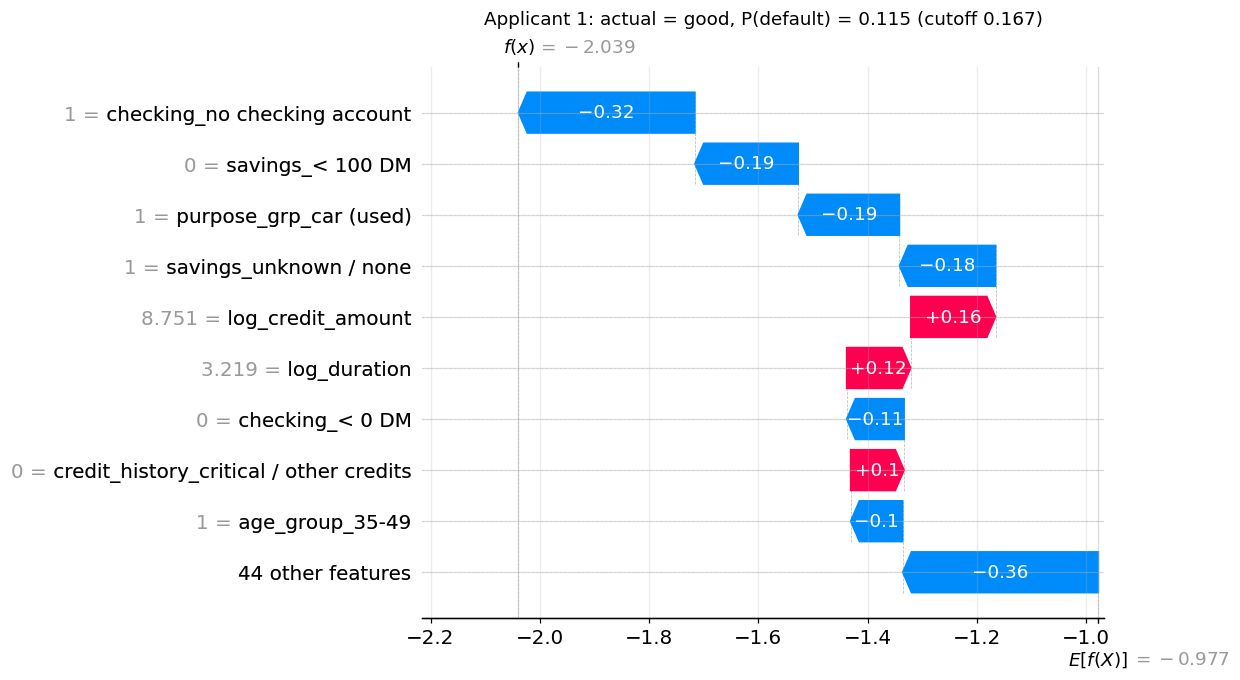

In [39]:
# Applicant 1: actual good, predicted good
shap.plots.waterfall(sv_lr[i_good], max_display=10, show=False)
plt.title(f"Applicant 1: actual = good, P(default) = {y_proba_lr[i_good]:.3f} (cutoff {THRESHOLD:.3f})", pad=28)
plt.show()

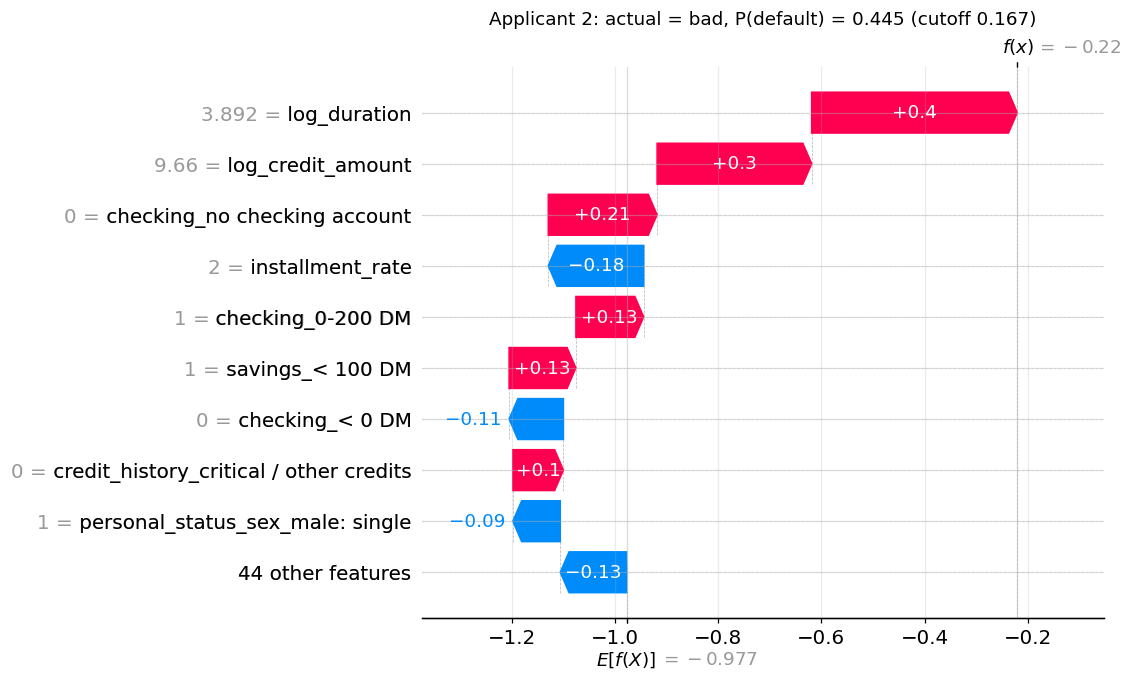

In [40]:
# Applicant 2: actual bad (defaulted), predicted bad
shap.plots.waterfall(sv_lr[i_bad], max_display=10, show=False)
plt.title(f"Applicant 2: actual = bad, P(default) = {y_proba_lr[i_bad]:.3f} (cutoff {THRESHOLD:.3f})", pad=28)
plt.show()

## (ii) Random Forest

### Data Loading and Verify Train-Test Split

We load the feature-engineered German Credit dataset from the above  and use the predefined stratified 80/20 train-test split (random_state=42).

The training set is used for model fitting and hyperparameter tuning through cross-validation, while the test set is reserved exclusively for final model evaluation.

The target variable is `default`, and the `split` column is excluded from the predictors to prevent data leakage.

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

DATA_PATH = 'data/processed/german_clean_modified.csv'
data_rf = pd.read_csv(DATA_PATH)
assert {'default', 'split'}.issubset(data_rf.columns)
assert set(data_rf['split'].unique()) == {'train', 'test'}
assert data_rf['default'].isin([0, 1]).all()
assert not data_rf.isna().any().any(), 'Review missing values before fitting.'
rf_train_df = data_rf.loc[data_rf['split'].eq('train')].copy()
rf_test_df = data_rf.loc[data_rf['split'].eq('test')].copy()
rf_X_train = rf_train_df.drop(columns=['default', 'split'])
rf_X_test = rf_test_df.drop(columns=['default', 'split'])
rf_y_train = rf_train_df['default'].astype(int)
rf_y_test = rf_test_df['default'].astype(int)
assert rf_X_train.columns.equals(rf_X_test.columns)
print('Shape:', data_rf.shape, '| Train:', rf_X_train.shape, '| Test:', rf_X_test.shape)
print('Default rates:', rf_y_train.mean(), rf_y_test.mean())
print('Feature types:', rf_X_train.dtypes.value_counts().to_dict())

Shape: (1000, 40) | Train: (800, 38) | Test: (200, 38)
Default rates: 0.3 0.3
Feature types: {dtype('O'): 18, dtype('int64'): 11, dtype('float64'): 9}


### Feature Sets and Model Design Rationale

Three Random Forest configurations are developed to evaluate the effects of hyperparameter tuning and feature reduction on credit default prediction. All models use the same stratified 80/20 train-test split established in section 12 of part (b) (`random_state=42`), with categorical variables transformed using one-hot encoding. Numerical variables are retained without scaling, as Random Forest models do not require feature standardization.

#### Baseline Model: Standard Random Forest

The baseline model follows the Random Forest implementation introduced in **Chapter 7 (Notebook 01)**, using 100 decision trees (`n_estimators=100`) with the remaining hyperparameters set to their scikit-learn defaults. All 38 predictors from feature engineering is retained, including original borrower characteristics and engineered features. After one-hot encoding, the model uses 98 input features.

**Purpose:** To establish a benchmark for evaluating whether hyperparameter tuning and feature reduction improve predictive performance.

#### Model 1: Hyperparameter-Tuned Random Forest (Full Features)

Model 1 retains the same 38 predictors as the baseline, allowing the effects of hyperparameter tuning to be examined without changing the feature set.

Hyperparameters are optimized using `RandomizedSearchCV` with 30 candidate configurations and stratified five-fold cross-validation (150 fits). ROC-AUC is used as the optimization metric because it measures the model's ability to distinguish defaulting from non-defaulting borrowers across classification thresholds.

The search considers the number of trees (`n_estimators`), maximum tree depth (`max_depth`), minimum samples required for splitting (`min_samples_split`), minimum samples per leaf (`min_samples_leaf`), number of features considered at each split (`max_features`), and class weighting (`class_weight`).

**Purpose:** To assess whether optimizing model complexity and class weighting improves predictive performance relative to the standard Random Forest.

#### Model 2: Hyperparameter-Tuned Random Forest (Reduced Features)

Model 2 investigates whether a simpler feature set can achieve comparable predictive performance while reducing redundancy and improving interpretability. The feature set is reduced from **38 to 21 predictors** using domain-based reasoning rather than test-set performance.

The following features are excluded:

- **Log transformations (`log_*`):** These contain overlapping information with the original numerical variables, such as `duration`, `credit_amount`, and `age`. Random Forest can capture non-linear relationships without requiring logarithmic transformations.
- **Duplicated categorical representations:** `emp_category`, `emp_years`, `purpose_grp`, `age_group`, and `amount_bin` are removed because their underlying information is already represented by the original employment

In [46]:
drop_reduced = [c for c in rf_X_train.columns if c.startswith('log_')]

drop_reduced += [
    'emp_category', 'emp_years', 'purpose_grp', 'age_group',
    'amount_bin', 'monthly_payment', 'income_index', 'lti',
    'total_dti', 'dti', 'other_installments'
]

drop_reduced = sorted(set(drop_reduced) & set(rf_X_train.columns))

full_features = rf_X_train.columns.tolist()
reduced_features = [c for c in full_features if c not in drop_reduced]

assert reduced_features and len(reduced_features) < len(full_features)

print('Full:', len(full_features), 'Reduced:', len(reduced_features))
print('Removed:', drop_reduced)
print('Retained:', reduced_features)

Full: 38 Reduced: 21
Removed: ['age_group', 'amount_bin', 'dti', 'emp_category', 'emp_years', 'income_index', 'log_age', 'log_credit_amount', 'log_duration', 'log_income_index', 'log_lti', 'log_monthly_payment', 'lti', 'monthly_payment', 'other_installments', 'purpose_grp', 'total_dti']
Retained: ['checking', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings', 'employment', 'installment_rate', 'personal_status_sex', 'other_debtors', 'residence_since', 'property', 'age', 'other_installment', 'housing', 'existing_credits', 'job', 'dependents', 'telephone', 'foreign_worker', 'sex']


### One-hot encoding, Shared Preprocessing and Cross-Validation

Random Forest requires numerical inputs. We therefore use one-hot encoding for categorical variables while retaining numerical features for all three models. 

Preprocessing is fitted only on the training set to prevent data leakage. The same fitted transformation is subsequently applied to the test set.

In [47]:
random_state = 42
rf_threshold = 1 / 6

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

params = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [5, 10, 15, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__class_weight': [None, 'balanced']
}

def make_pipeline(features, n_estimators=100):
    subset = rf_X_train[features]
    categorical = subset.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
    numeric = subset.select_dtypes(include='number').columns.tolist()

    transform = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
        ('num', 'passthrough', numeric)
    ])

    return Pipeline([
        ('preprocessor', transform),
        ('classifier', RandomForestClassifier(
            n_estimators=n_estimators,
            random_state=random_state,
            n_jobs=1
        ))
    ])

def tune_model(features):
    search = RandomizedSearchCV(
        make_pipeline(features),
        params,
        n_iter=30,
        scoring='roc_auc',
        cv=cv,
        random_state=random_state,
        n_jobs=-1,
        verbose=1,
        refit=True
    )
    search.fit(rf_X_train[features], rf_y_train)
    return search

# Show exactly what gets one-hot encoded in each feature set.
for label, features in [
    ('Baseline / Model 1 (all)', full_features),
    ('Model 2 (reduced)', reduced_features)
]:
    cat_cols = rf_X_train[features].select_dtypes(
        include=['object', 'category', 'string']
    ).columns.tolist()

    num_cols = rf_X_train[features].select_dtypes(
        include='number'
    ).columns.tolist()

    print(f'\n{label}: {len(features)} raw predictors; {len(cat_cols)} categorical, {len(num_cols)} numeric')
    print('One-hot encoded categorical columns:', cat_cols)
    print('Passed-through numerical columns:', num_cols)


Baseline / Model 1 (all): 38 raw predictors; 18 categorical, 20 numeric
One-hot encoded categorical columns: ['checking', 'credit_history', 'purpose', 'savings', 'employment', 'personal_status_sex', 'other_debtors', 'property', 'other_installment', 'housing', 'job', 'telephone', 'foreign_worker', 'sex', 'emp_category', 'purpose_grp', 'age_group', 'amount_bin']
Passed-through numerical columns: ['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'dependents', 'log_duration', 'log_credit_amount', 'log_age', 'monthly_payment', 'dti', 'income_index', 'lti', 'total_dti', 'other_installments', 'log_monthly_payment', 'log_income_index', 'log_lti', 'emp_years']

Model 2 (reduced): 21 raw predictors; 14 categorical, 7 numeric
One-hot encoded categorical columns: ['checking', 'credit_history', 'purpose', 'savings', 'employment', 'personal_status_sex', 'other_debtors', 'property', 'other_installment', 'housing', 'job', 'telephone', 'foreign_worker', 's

### Fit baseline and tune both candidate feature sets (Training)

In [51]:
from sklearn.model_selection import cross_val_predict

baseline = make_pipeline(full_features, n_estimators=100)

baseline_cv_auc = cross_val_score(
    baseline, rf_X_train[full_features], rf_y_train,
    cv=cv, scoring='roc_auc', n_jobs=-1
).mean()

baseline.fit(rf_X_train[full_features], rf_y_train)

model1_search = tune_model(full_features)
model2_search = tune_model(reduced_features)

model1 = model1_search.best_estimator_
model2 = model2_search.best_estimator_

fitted = {
    'Baseline (full)': (baseline, full_features),
    'Model 1 (full tuned)': (model1, full_features),
    'Model 2 (reduced tuned)': (model2, reduced_features)
}

cv_scores = {
    'Baseline (full)': baseline_cv_auc,
    'Model 1 (full tuned)': model1_search.best_score_,
    'Model 2 (reduced tuned)': model2_search.best_score_
}

cv_rows = []

for name, (pipe, features) in fitted.items():
    probabilities = cross_val_predict(
        pipe,
        rf_X_train[features],
        rf_y_train,
        cv=cv,
        method='predict_proba',
        n_jobs=-1
    )[:, 1]

    labels = (probabilities > rf_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        rf_y_train, labels, labels=[0, 1]
    ).ravel()

    cv_rows.append({
        'Model': name,
        'Features': len(features),
        'CV ROC-AUC': cv_scores[name],
        'CV cost per applicant': (5 * fn + fp) / len(rf_y_train)
    })

cv_table = pd.DataFrame(cv_rows)

display(cv_table.round(4))

print('Model 1 best parameters:', model1_search.best_params_)
print('Model 2 best parameters:', model2_search.best_params_)

selected_by_cv = cv_table.loc[
    cv_table['CV cost per applicant'].idxmin(), 'Model'
]

print('Lowest training CV cost:', selected_by_cv)

rf_selected_model, rf_selected_features = fitted[selected_by_cv]

for name, pipe in [
    ('Baseline', baseline),
    ('Model 1', model1),
    ('Model 2', model2)
]:
    encoded_names = pipe.named_steps['preprocessor'].get_feature_names_out()
    print(f'{name}: {len(encoded_names)} encoded model inputs')

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits


,Model,Features,CV ROC-AUC,CV cost per applicant
0,Baseline (full),38,0.7896,0.5412
1,Model 1 (full tuned),38,0.7971,0.6962
2,Model 2 (reduced tuned),21,0.7934,0.5300


Model 1 best parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2', 'classifier__max_depth': 5, 'classifier__class_weight': 'balanced'}
Model 2 best parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10, 'classifier__class_weight': None}
Lowest training CV cost: Model 2 (reduced tuned)
Baseline: 98 encoded model inputs
Model 1: 98 encoded model inputs
Model 2: 63 encoded model inputs


### Final Comparison - Baseline vs Model 1 vs Model 2

In [52]:
fitted = {
    'Baseline (full)': (baseline, full_features),
    'Model 1 (full tuned)': (model1, full_features),
    'Model 2 (reduced tuned)': (model2, reduced_features)
}

rows, predictions = [], {}

for name, (pipe, features) in fitted.items():
    probabilities = pipe.predict_proba(rf_X_test[features])[:, 1]
    labels = (probabilities > rf_threshold).astype(int)
    predictions[name] = (probabilities, labels)

    tn, fp, fn, tp = confusion_matrix(rf_y_test, labels, labels=[0, 1]).ravel()

    rows.append({
        'Model': name,
        'Raw features': len(features),
        'Encoded features': len(pipe.named_steps['preprocessor'].get_feature_names_out()),
        'CV ROC-AUC': float(cv_table.loc[cv_table['Model'].eq(name), 'CV ROC-AUC'].iloc[0]),
        'Test ROC-AUC': roc_auc_score(rf_y_test, probabilities),
        'Accuracy': accuracy_score(rf_y_test, labels),
        'Precision': precision_score(rf_y_test, labels, zero_division=0),
        'Recall': recall_score(rf_y_test, labels, zero_division=0),
        'F1-score': f1_score(rf_y_test, labels, zero_division=0),
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp,
        'Cost per applicant': (5 * fn + fp) / len(rf_y_test)
    })

comparison = pd.DataFrame(rows).set_index('Model')
display(comparison.round(4))

print('Reminder: test metrics describe held-out performance, not a basis for retuning.')

# Explicit final predictions for the CV-selected Random Forest.
rf_selected_model, rf_selected_features = fitted[selected_by_cv]

rf_selected_test_prob = predictions[selected_by_cv][0]
rf_selected_test_pred = predictions[selected_by_cv][1]

rf_selected_tn, rf_selected_fp, rf_selected_fn, rf_selected_tp = confusion_matrix(
    rf_y_test, rf_selected_test_pred, labels=[0, 1]
).ravel()

rf_selected_cost = (5 * rf_selected_fn + rf_selected_fp) / len(rf_y_test)

print(f'\nCV-selected model: {selected_by_cv}')
print(f'Policy threshold: {rf_threshold:.6f} (flag if probability > threshold)')
print(f'Test ROC-AUC: {roc_auc_score(rf_y_test, rf_selected_test_prob):.4f}')
print(f'Test recall: {recall_score(rf_y_test, rf_selected_test_pred):.4f}')
print(f'Test precision: {precision_score(rf_y_test, rf_selected_test_pred, zero_division=0):.4f}')
print(f'TN={rf_selected_tn}, FP={rf_selected_fp}, FN={rf_selected_fn}, TP={rf_selected_tp}')
print(f'Cost per applicant: {rf_selected_cost:.4f}')

,Raw features,Encoded features,CV ROC-AUC,Test ROC-AUC,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP,Cost per applicant
Model,,,,,,,,,,,,,
Baseline (full),38,98,0.7896,0.7992,0.500,0.3667,0.9167,0.5238,45,95,5,55,0.600
Model 1 (full tuned),38,98,0.7971,0.7956,0.310,0.3030,1.0000,0.4651,2,138,0,60,0.690
Model 2 (reduced tuned),21,63,0.7934,0.8031,0.545,0.3946,0.9667,0.5604,51,89,2,58,0.495


Reminder: test metrics describe held-out performance, not a basis for retuning.

CV-selected model: Model 2 (reduced tuned)
Policy threshold: 0.166667 (flag if probability > threshold)
Test ROC-AUC: 0.8031
Test recall: 0.9667
Test precision: 0.3946
TN=51, FP=89, FN=2, TP=58
Cost per applicant: 0.4950


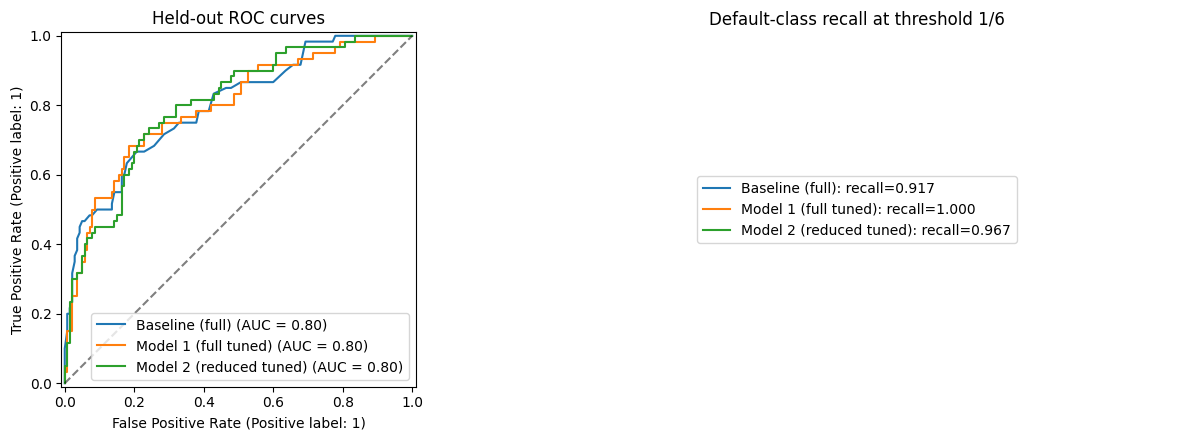

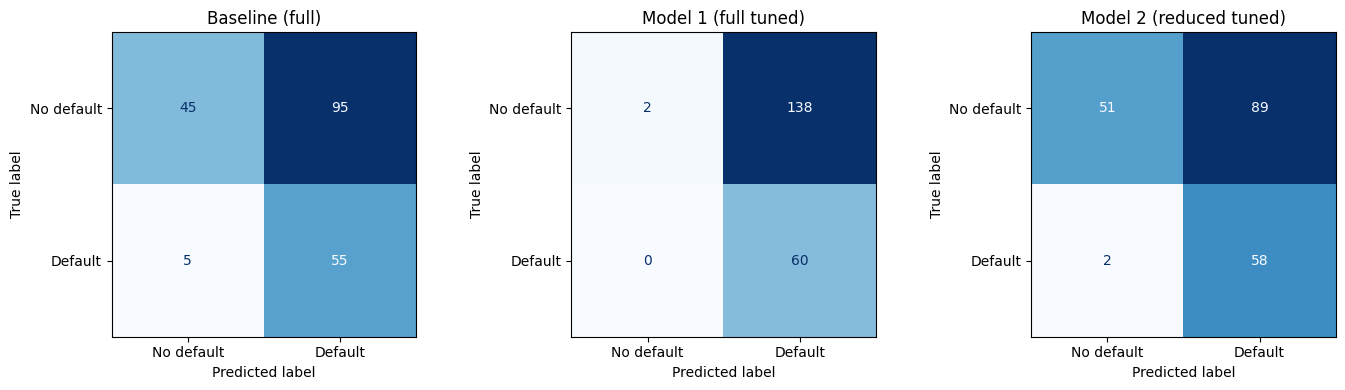

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, (prob, labels) in predictions.items():
    RocCurveDisplay.from_predictions(rf_y_test, prob, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('Held-out ROC curves')
for name, (prob, labels) in predictions.items():
    axes[1].plot([], [], label=f'{name}: recall={recall_score(rf_y_test, labels):.3f}')
axes[1].legend(loc='center')
axes[1].axis('off')
axes[1].set_title('Default-class recall at threshold 1/6')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, (prob, labels)) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(rf_y_test, labels, labels=[0, 1],
                                            display_labels=['No default', 'Default'],
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Summary of Random Forest 
Three Random Forest models were compared to assess the effects of hyperparameter tuning and feature reduction, using a cost-sensitive classification threshold of 1/6.

- **Baseline:** Achieved a CV ROC-AUC of 0.7896, with 50.0% test accuracy and 91.67% recall. Its cross-validation cost per applicant was 0.5412.
- **Model 1 (Full Tuned):** Achieved the highest CV ROC-AUC (0.7971) and recall (100%), successfully identifying all actual defaulters. However, it produced 138 false positives, resulting in the lowest accuracy (31.0%) and highest cross-validation cost per applicant (0.6962).
- **Model 2 (Reduced Tuned):** Achieved the highest test ROC-AUC (0.8031), accuracy (54.5%), and F1-score (0.5604), while maintaining high recall (96.67%). Using only 21 predictors, it also achieved the lowest cross-validation cost per applicant (0.5300).

**Conclusion:** Model 2 is selected for SHAP explainability because it achieved the lowest estimated cross-validation misclassification cost while maintaining competitive discriminatory performance with fewer predictors. Although Model 1 achieved the highest CV ROC-AUC, its substantially higher false-positive rate resulted in greater misclassification costs. Model 2 therefore offers a more favourable balance between cost efficiency, predictive performance, and model simplicity.

### Implement SHAP with Selected Model 2

In [54]:
import shap
# Select the model using training CV only, not held-out test metrics.
explain_model, explain_features = fitted[selected_by_cv]
prep = explain_model.named_steps['preprocessor']
forest = explain_model.named_steps['classifier']
X_encoded = prep.transform(rf_X_test[explain_features])
if hasattr(X_encoded, 'toarray'):
    X_encoded = X_encoded.toarray()
X_encoded = pd.DataFrame(X_encoded, columns=prep.get_feature_names_out(), index=rf_X_test.index)
explainer = shap.TreeExplainer(forest)
shap_all = explainer(X_encoded)
shap_default = shap_all[:, :, 1] if shap_all.values.ndim == 3 else shap_all
proba = predictions[selected_by_cv][0]
reconstructed = shap_default.base_values + shap_default.values.sum(axis=1)
error = np.max(np.abs(reconstructed - proba))
print('Explained model:', selected_by_cv)
print('Maximum SHAP reconstruction difference:', error)
assert error < 1e-6, 'Check the SHAP output scale/class selection.' 

Explained model: Model 2 (reduced tuned)
Maximum SHAP reconstruction difference: 1.2212453270876722e-15


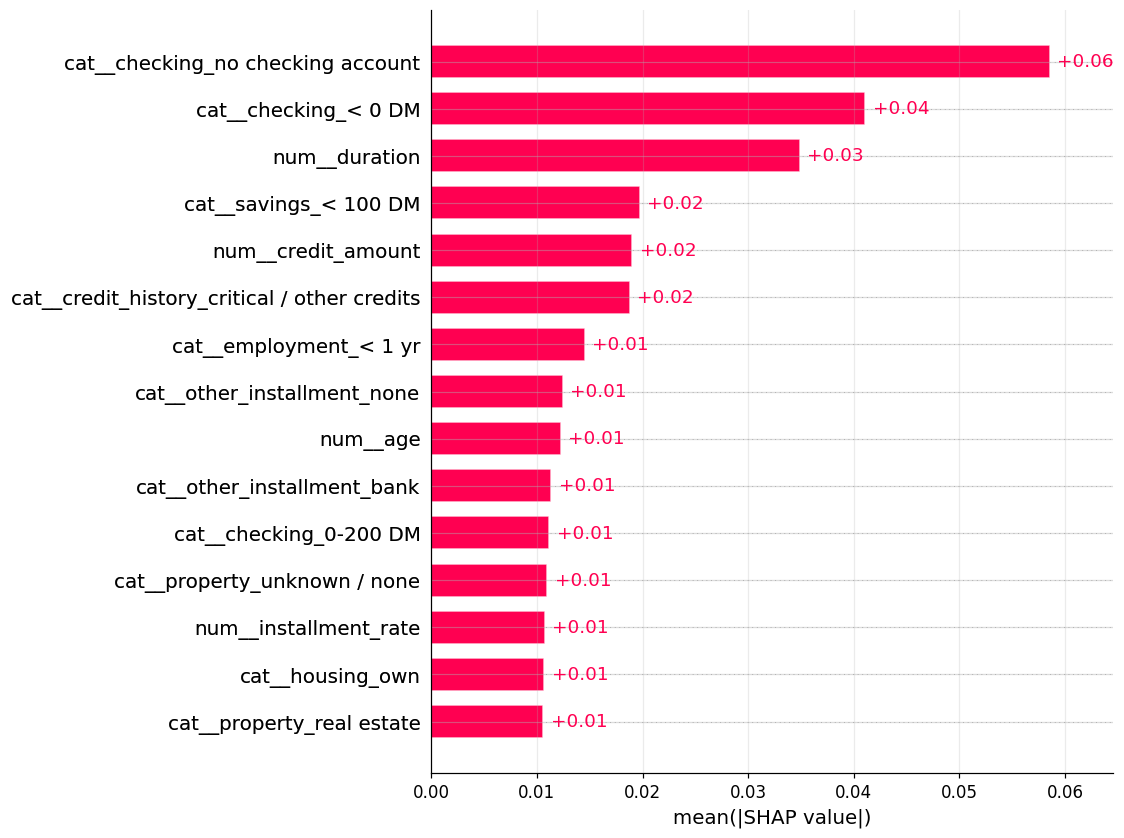

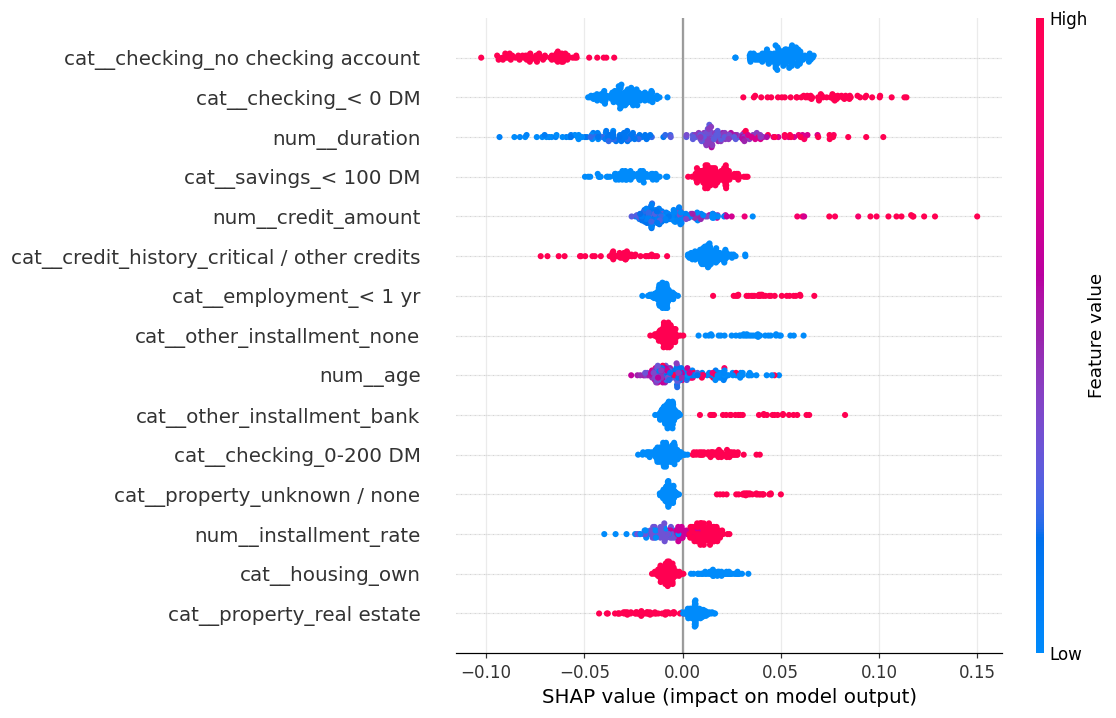

Highest predicted default risk: 99 76.41%


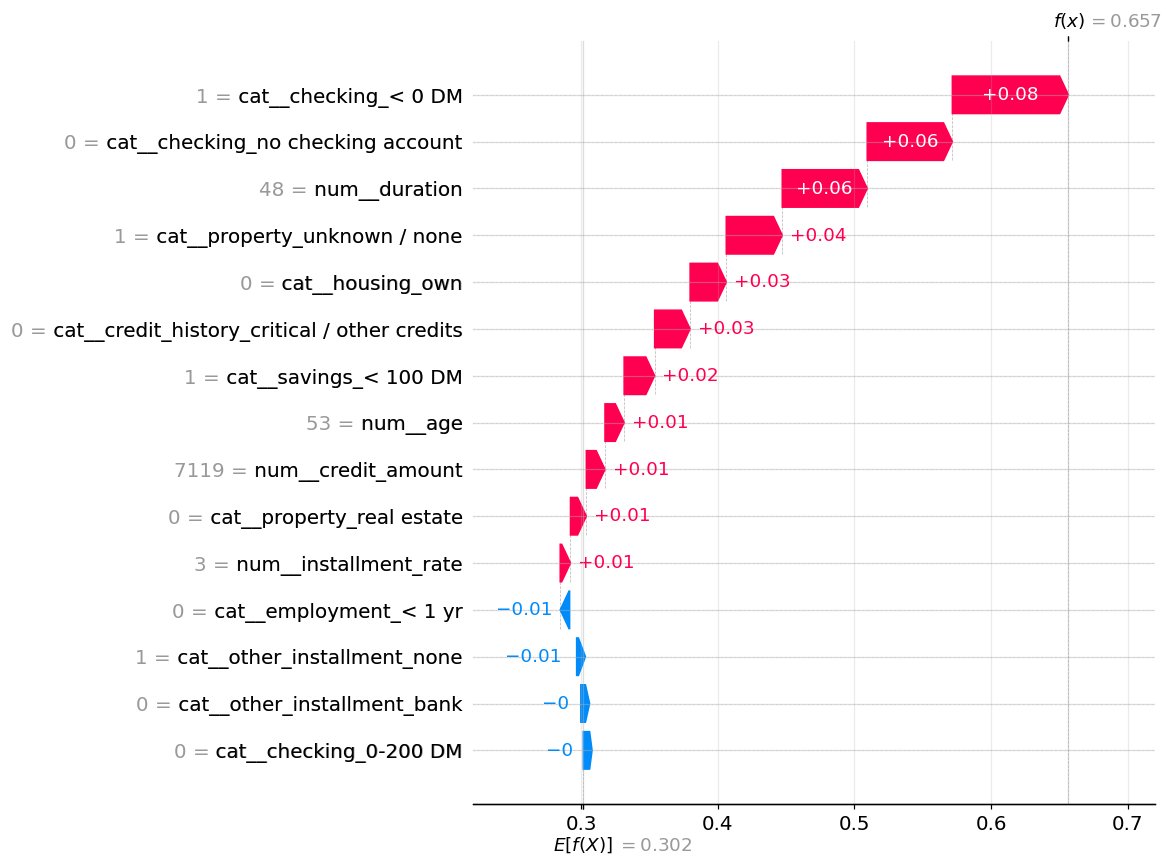

Lowest predicted default risk: 49 2.15%


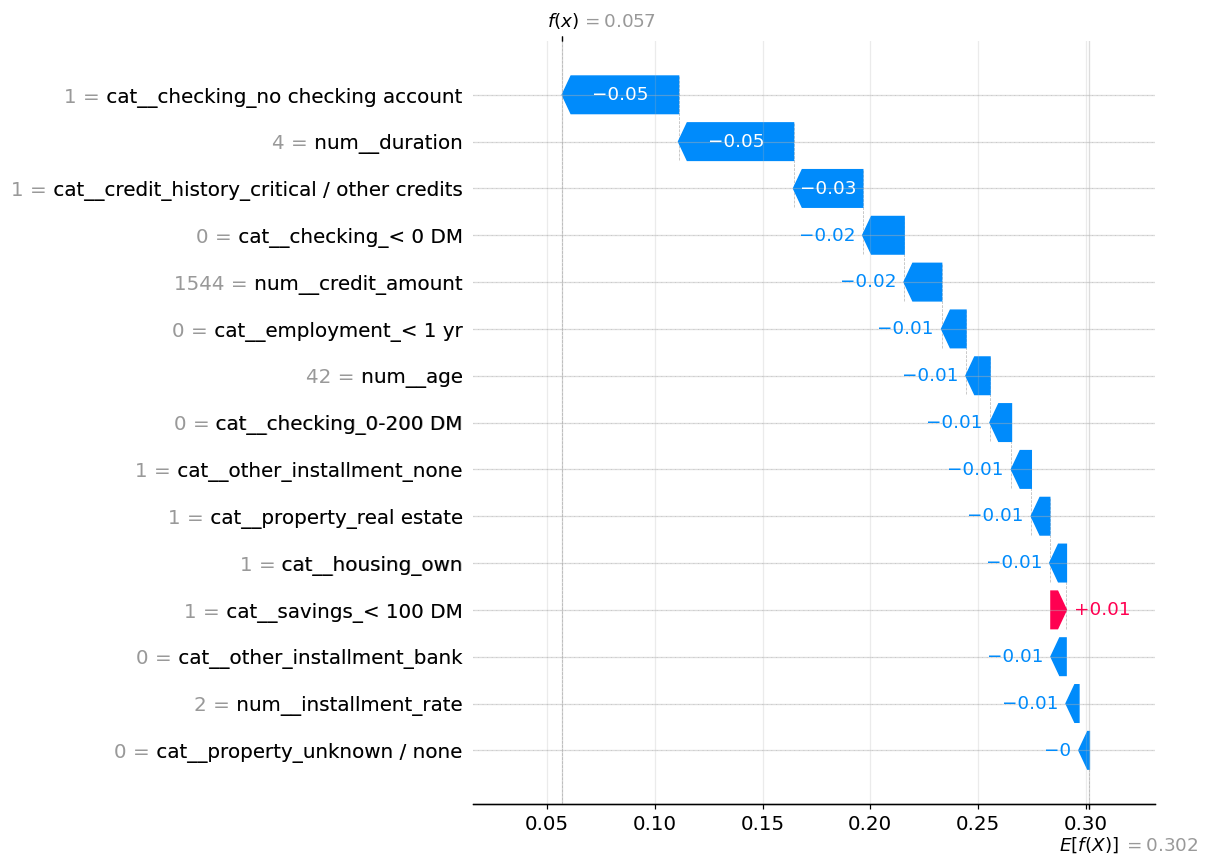

In [ ]:
# Select top 15 features based on mean absolute SHAP values
top15_idx = np.argsort(
    np.abs(shap_default.values).mean(axis=0)
)[-15:][::-1]

# SHAP bar plot: Top 15 features only
shap.plots.bar(shap_default[:, top15_idx], max_display=15)

shap.plots.beeswarm(
    shap_default[:, top15_idx],
    max_display=15,
    group_remaining_features=False
)

hi, lo = int(np.argmax(proba)), int(np.argmin(proba))

print('Highest predicted default risk:', hi, f'{proba[hi]:.2%}')
shap.plots.waterfall(shap_default[hi, top15_idx], max_display=15)

print('Lowest predicted default risk:', lo, f'{proba[lo]:.2%}')
shap.plots.waterfall(shap_default[lo, top15_idx], max_display=15)

## (iii) AdaBoost

AdaBoost fits many small decision trees one after another. After each tree, the applicants it got wrong get more weight, so the next tree focuses on them. The final prediction is a weighted vote of all the trees, with better trees getting a bigger vote.

All variables in this section end in `_ada` (e.g. `x_train_ada`) so they don't overwrite the logistic regression and random forest variables.

### 1) Imports

In [3]:
# numpy, pandas and matplotlib are already imported in part (a)
from sklearn.tree import DecisionTreeClassifier          # the small tree that AdaBoost combines
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.calibration import CalibratedClassifierCV  # fixes AdaBoost's probabilities (step 6)
from sklearn.base import clone                           # makes an unfitted copy of a model
from sklearn.metrics import accuracy_score, zero_one_loss
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_auc_score, roc_curve

### 2) Load data and choose features
We load the part (b) file and use its `split` column, so AdaBoost is tested on the same 200 applicants as the other models.

Trees only care about the *order* of values, not their scale, so there is no need for scaling or the `log_` columns. We also leave out columns that repeat information already in the list:

| Left out | Reason |
|---|---|
| `log_duration`, `log_credit_amount`, `log_age`, `log_monthly_payment`, `log_income_index`, `log_lti` | same order as the original columns, so trees split them the same way |
| `dti` | identical to `installment_rate` |
| `purpose`, `employment` | replaced by `purpose_grp` and `emp_category` + `emp_years` |
| `age_group`, `amount_bin` | trees choose their own cut points for age and amount |
| `sex` | already contained in `personal_status_sex` |

In [4]:
# Load the cleaned and feature-engineered data from part (b)
data_ada = pd.read_csv("data/processed/german_clean_modified.csv")

# Numeric features: original columns + part (b) affordability and tenure features
num_features_ada = ["duration", "credit_amount", "installment_rate", "residence_since", "age",
                    "existing_credits", "dependents",
                    "monthly_payment", "income_index", "lti", "total_dti", "other_installments", "emp_years"]

# Categorical features
cat_features_ada = ["checking", "credit_history", "purpose_grp", "savings", "emp_category",
                    "personal_status_sex", "other_debtors", "property", "other_installment",
                    "housing", "job", "telephone", "foreign_worker"]

# Define target column (1 = bad / default, 0 = good)
target = "default"

# Each category level becomes its own 0/1 column
X_ada = pd.get_dummies(data_ada[num_features_ada + cat_features_ada], columns=cat_features_ada, dtype=int)
y_ada = data_ada[target]

# Use the train/test split from part (b)
is_train = data_ada["split"] == "train"
x_train_ada, x_test_ada = X_ada[is_train], X_ada[~is_train]
y_train_ada, y_test_ada = y_ada[is_train], y_ada[~is_train]

print("Train:", x_train_ada.shape, "  Test:", x_test_ada.shape)
print(f"Default rate  train: {y_train_ada.mean():.3f}   test: {y_test_ada.mean():.3f}")

Train: (800, 65)   Test: (200, 65)
Default rate  train: 0.300   test: 0.300


### 3) Baseline: AdaBoost with decision stumps
Testing the same setup as the ch07 notebooks.
100 rounds of stumps (trees with a single split). This is our baseline before tuning.

In [5]:
ada_base = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),  # weak learner: a stump (one split)
    n_estimators=100,                               # number of boosting rounds (stumps)
    learning_rate=1.0,                              # how much each new stump's vote counts
    random_state=42,
)
ada_base.fit(x_train_ada, y_train_ada)

# Probability of default (column 1) for each test applicant
y_pred_proba = ada_base.predict_proba(x_test_ada)[:, 1]
acc = accuracy_score(y_test_ada, ada_base.predict(x_test_ada))
auc = roc_auc_score(y_test_ada, y_pred_proba)
print(f"Baseline AdaBoost - Accuracy: {acc:.3f}, AUC: {auc:.3f}")

Baseline AdaBoost - Accuracy: 0.755, AUC: 0.777


### 4) Tuning with cross-validation
We tune:
- `n_estimators`: the number of rounds. Too many can overfit.
- `learning_rate`: how much each tree counts. A smaller rate usually needs more rounds, so the two are tuned together.
- `estimator__max_depth`: stumps (1) or two-level trees (2). Depth 2 lets a tree combine two features, e.g. short loan *and* no checking account.

Each combination is scored by 5-fold cross-validation on the **training set only**. The test set stays untouched until step 7.

We rank combinations by **AUC**, which measures how well the model ranks bad applicants above good ones, whatever cutoff is used.

In [6]:
# Settings to try: 5 x 4 x 2 = 40 combinations
param_grid_ada = {
    "n_estimators": [50, 100, 200, 400, 800],
    "learning_rate": [0.05, 0.1, 0.5, 1.0],
    "estimator__max_depth": [1, 2],   # "estimator__" means: a setting of the tree inside AdaBoost
}

# 5 folds; stratified so every fold keeps about 30% defaults
cv_ada = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

ada_grid = GridSearchCV(
    AdaBoostClassifier(estimator=DecisionTreeClassifier(), random_state=42),
    param_grid_ada,
    scoring="roc_auc",   # pick the combination with the highest mean CV AUC
    cv=cv_ada,
    n_jobs=-1,
)
ada_grid.fit(x_train_ada, y_train_ada)

print("Best parameters:", ada_grid.best_params_)
print(f"Best CV AUC: {ada_grid.best_score_:.4f}")

# Show the top 5 combinations
cv_results_ada = pd.DataFrame(ada_grid.cv_results_)
cv_results_ada[["param_estimator__max_depth", "param_learning_rate", "param_n_estimators",
                "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False).head(5).round(4)

Best parameters: {'estimator__max_depth': 1, 'learning_rate': 0.5, 'n_estimators': 400}
Best CV AUC: 0.7963


,param_estimator__max_depth,param_learning_rate,param_n_estimators,mean_test_score,std_test_score
13,1,0.5,400,0.7963,0.0384
14,1,0.5,800,0.7960,0.0322
12,1,0.5,200,0.7938,0.0371
31,2,0.5,100,0.7926,0.0345
29,2,0.1,800,0.7892,0.0362


### 5) Error over boosting iterations
Following the ESL Fig. 10.2 plot in ch07: the error after each round of the tuned model. `staged_predict` returns the prediction after round 1, 2, 3, and so on.

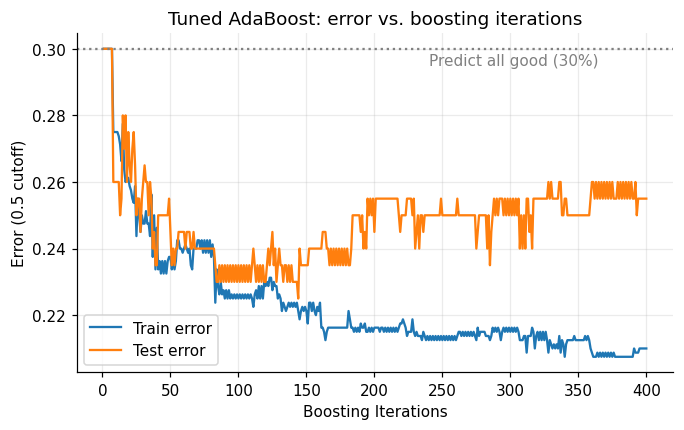

Final train error: 0.210   Final test error: 0.255


In [7]:
import warnings
# staged_predict triggers a harmless scikit-learn warning about feature names; hide only that message
warnings.filterwarnings("ignore", message="X does not have valid feature names")

# GridSearchCV refits the best combination on the whole training set
ada_best = ada_grid.best_estimator_

# Error after each boosting round, using the default 0.5 cutoff
train_err = [zero_one_loss(y_train_ada, y_pred) for y_pred in ada_best.staged_predict(x_train_ada)]
test_err  = [zero_one_loss(y_test_ada,  y_pred) for y_pred in ada_best.staged_predict(x_test_ada)]
rounds = range(1, len(train_err) + 1)

plt.figure(figsize=(7, 4))
plt.plot(rounds, train_err, label="Train error")
plt.plot(rounds, test_err, label="Test error")

# Reference line: predicting "good" for everyone gives 30% error
plt.axhline(0.3, linestyle=":", color="gray")
plt.text(len(train_err) * 0.6, 0.295, "Predict all good (30%)", color="gray")

plt.xlabel("Boosting Iterations")
plt.ylabel("Error (0.5 cutoff)")
plt.title("Tuned AdaBoost: error vs. boosting iterations")
plt.legend()
plt.show()

print(f"Final train error: {train_err[-1]:.3f}   Final test error: {test_err[-1]:.3f}")

### 6) Calibrating the probabilities
Part (a) showed the cost-optimal rule is to reject an applicant when P(default) > 1/6. That only works if the probabilities are realistic.

AdaBoost's `predict_proba` is built from the trees' weighted vote, not estimated as a probability, so its values bunch up in a narrow band around 0.5. With a 1/6 cutoff, every applicant would be rejected.

We fix this with Platt scaling (`CalibratedClassifierCV(method="sigmoid")`). It fits a logistic curve that maps AdaBoost's score to a probability. To avoid using the same data twice, it fits AdaBoost on 4/5 of the training data, fits the curve on the remaining 1/5, repeats this for all 5 folds and averages. The ranking of applicants barely changes, so AUC stays about the same. Only the probability scale changes.

Raw P(default) range on test: 0.26 to 0.61
Calibrated P(default) range on test: 0.01 to 0.88


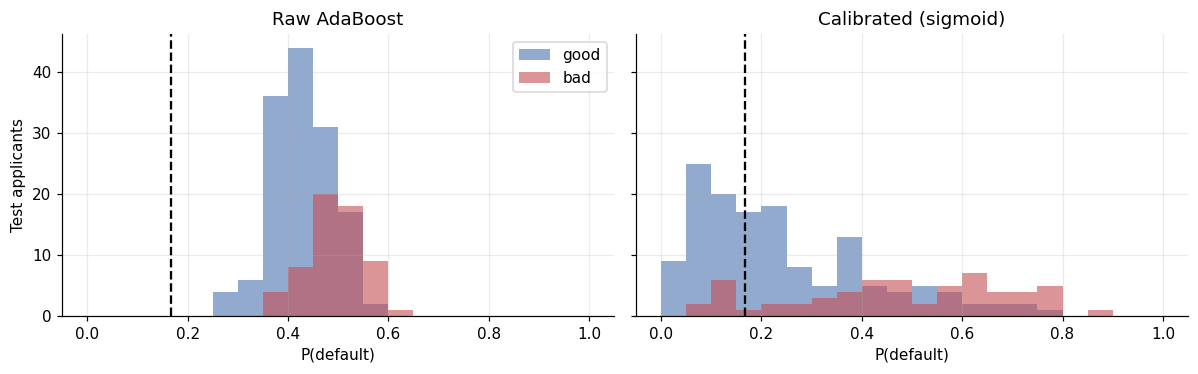

In [8]:
# Before: the raw AdaBoost probabilities
p_raw = ada_best.predict_proba(x_test_ada)[:, 1]

# Calibrate: clone() gives a fresh, unfitted copy of the tuned model with the same settings
ada_cal = CalibratedClassifierCV(clone(ada_best), method="sigmoid", cv=cv_ada)
ada_cal.fit(x_train_ada, y_train_ada)

# After: the calibrated probabilities
p_cal = ada_cal.predict_proba(x_test_ada)[:, 1]

print(f"Raw P(default) range on test: {p_raw.min():.2f} to {p_raw.max():.2f}")
print(f"Calibrated P(default) range on test: {p_cal.min():.2f} to {p_cal.max():.2f}")

# Plot both distributions with the 1/6 cutoff
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, p, title in zip(ax, [p_raw, p_cal], ["Raw AdaBoost", "Calibrated (sigmoid)"]):
    a.hist(p[y_test_ada == 0], bins=20, range=(0, 1), alpha=.6, color=C_GOOD, label="good")
    a.hist(p[y_test_ada == 1], bins=20, range=(0, 1), alpha=.6, color=C_BAD, label="bad")
    a.axvline(1 / 6, linestyle="--", color="black")
    a.set_title(title)
    a.set_xlabel("P(default)")
ax[0].set_ylabel("Test applicants")
ax[0].legend()
plt.tight_layout()
plt.show()

#### Cross-validated AUC and cost (same table as logistic regression)
For each stage we report the 5-fold CV AUC, its standard deviation across folds, and the CV cost per applicant at the 1/6 cutoff, all on the **training rows only**. The cost uses out-of-fold P(default): each training applicant is scored by a model that did not see them. The raw (uncalibrated) rows show why step 6 is needed.

In [9]:
# CV AUC, AUC SD and CV cost per applicant on the training set only (same method as the logistic regression table).
# cost per applicant = (5*FN + 1*FP) / n   (FN = defaulter approved, FP = good borrower rejected)
from sklearn.model_selection import cross_val_predict

stages_ada = {
    "3 Baseline (100 stumps, learning rate 1.0)": ada_base,
    f"4 Tuned ({ada_best.n_estimators} trees, depth {ada_best.estimator.max_depth}, "
    f"learning rate {ada_best.learning_rate})": ada_best,
    "6 Tuned + sigmoid calibration": CalibratedClassifierCV(clone(ada_best), method="sigmoid", cv=cv_ada),
}

rows_ada = []
for stage, model in stages_ada.items():
    # Out-of-fold P(default); clone() so each stage starts from an unfitted model (about 1 minute for the calibrated stage)
    p_oof = cross_val_predict(clone(model), x_train_ada, y_train_ada, cv=cv_ada, method="predict_proba")[:, 1]

    # AUC in each of the same 5 folds (equivalent to cross_val_score, without refitting)
    fold_auc = np.array([roc_auc_score(y_train_ada.iloc[val], p_oof[val])
                         for _, val in cv_ada.split(x_train_ada, y_train_ada)])

    high_risk = p_oof > 1 / 6
    fn = int((~high_risk & (y_train_ada.values == 1)).sum())
    fp = int((high_risk & (y_train_ada.values == 0)).sum())
    rows_ada.append((stage, round(fold_auc.mean(), 4), round(fold_auc.std(), 4),
                     round((5 * fn + fp) / len(y_train_ada), 3)))

cv_table_ada = pd.DataFrame(rows_ada, columns=["Stage", "CV AUC", "AUC SD", "CV cost per applicant"])
print(cv_table_ada.to_string(index=False))

                                          Stage  CV AUC  AUC SD  CV cost per applicant
     3 Baseline (100 stumps, learning rate 1.0)  0.7844  0.0399                  0.700
4 Tuned (400 trees, depth 1, learning rate 0.5)  0.7963  0.0384                  0.700
                  6 Tuned + sigmoid calibration  0.7969  0.0388                  0.522


### 7) Testing
From here on we use the calibrated model `ada_cal` on the test set, with the cost-optimal cutoff of 1/6 from part (a).

In [10]:
# Flag as bad (1) when P(default) > 1/6
THRESHOLD = 1 / 6
y_proba_ada = ada_cal.predict_proba(x_test_ada)[:, 1]
y_pred_ada = (y_proba_ada > THRESHOLD).astype(int)

#accuracy
accuracy = accuracy_score(y_test_ada, y_pred_ada)
print(f"Accuracy: {accuracy:.4f}")

#confusion matrix
# Rows = actual (0 good, 1 bad), columns = predicted
print("Confusion Matrix:")
print(confusion_matrix(y_test_ada, y_pred_ada))

#misclassification report
print("\nClassification Report:")
print(classification_report(y_test_ada, y_pred_ada))

Accuracy: 0.5650
Confusion Matrix:
[[61 79]
 [ 8 52]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.44      0.58       140
           1       0.40      0.87      0.54        60

    accuracy                           0.56       200
   macro avg       0.64      0.65      0.56       200
weighted avg       0.74      0.56      0.57       200



In [11]:
#misclassification cost
def cost_per_applicant(y_true, y_pred):
    """Average cost: 5 per bad borrower approved (FN) + 1 per good borrower rejected (FP)."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return (5 * fn + 1 * fp) / len(y_true)

n_test = len(y_test_ada)
cost_table_ada = pd.Series({
    "AdaBoost, cutoff 1/6": cost_per_applicant(y_test_ada, y_pred_ada),
    "AdaBoost, cutoff 0.5": cost_per_applicant(y_test_ada, (y_proba_ada > 0.5).astype(int)),
    "Approve everyone":     cost_per_applicant(y_test_ada, np.zeros(n_test, dtype=int)),
    "Reject everyone":      cost_per_applicant(y_test_ada, np.ones(n_test, dtype=int)),
}, name="cost per applicant").round(3)
cost_table_ada


AdaBoost, cutoff 1/6    0.595
AdaBoost, cutoff 0.5    0.880
Approve everyone        1.500
Reject everyone         0.700
Name: cost per applicant, dtype: float64

#### Test summary and confusion matrix (same layout as logistic regression)

ROC-AUC:   0.7993
Accuracy:  0.5650
Precision: 0.3969
Recall:    0.8667


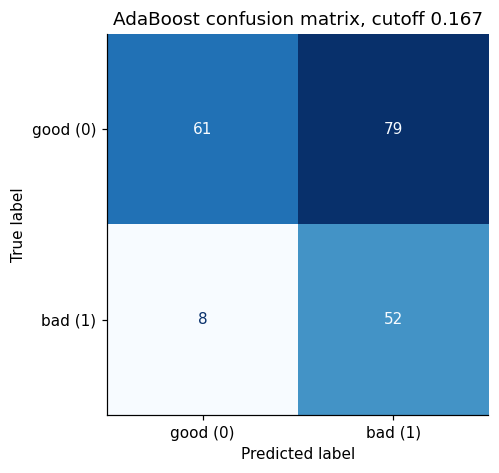

In [12]:
from sklearn.metrics import precision_score, recall_score, ConfusionMatrixDisplay

# Same summary as the logistic regression section (calibrated model, cutoff 1/6)
print(f"ROC-AUC:   {roc_auc_score(y_test_ada, y_proba_ada):.4f}")
print(f"Accuracy:  {accuracy_score(y_test_ada, y_pred_ada):.4f}")
print(f"Precision: {precision_score(y_test_ada, y_pred_ada):.4f}")
print(f"Recall:    {recall_score(y_test_ada, y_pred_ada):.4f}")

# Confusion matrix (own figure): rows = actual (0 good, 1 bad), columns = predicted
fig, ax = plt.subplots(figsize=(5, 4.4))
ConfusionMatrixDisplay(confusion_matrix(y_test_ada, y_pred_ada),
                       display_labels=["good (0)", "bad (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.grid(False)
ax.set_title(f"AdaBoost confusion matrix, cutoff {THRESHOLD:.3f}")
plt.tight_layout()
plt.show()

#### Comparing the three AdaBoost variations (same plots as random forest)
The three stages from the CV table, scored on the test set at the 1/6 cutoff: the baseline and the tuned model without calibration, and the final tuned + calibrated model. The ROC curves of the two tuned models almost overlap, because calibration only rescales the probabilities and keeps the ranking. The confusion matrices show the difference: without calibration, the probabilities are bunched well above 1/6, so (nearly) every applicant is rejected.

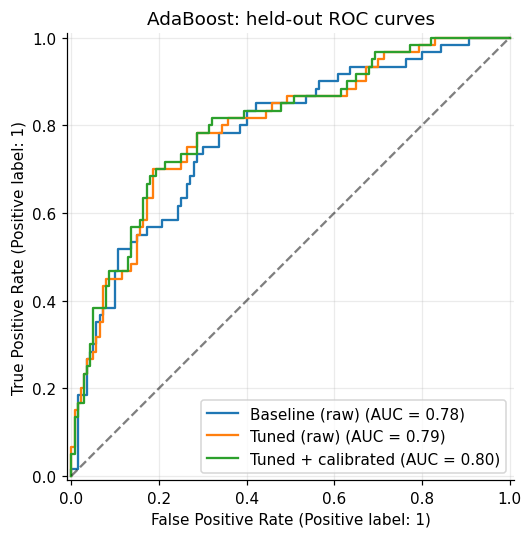

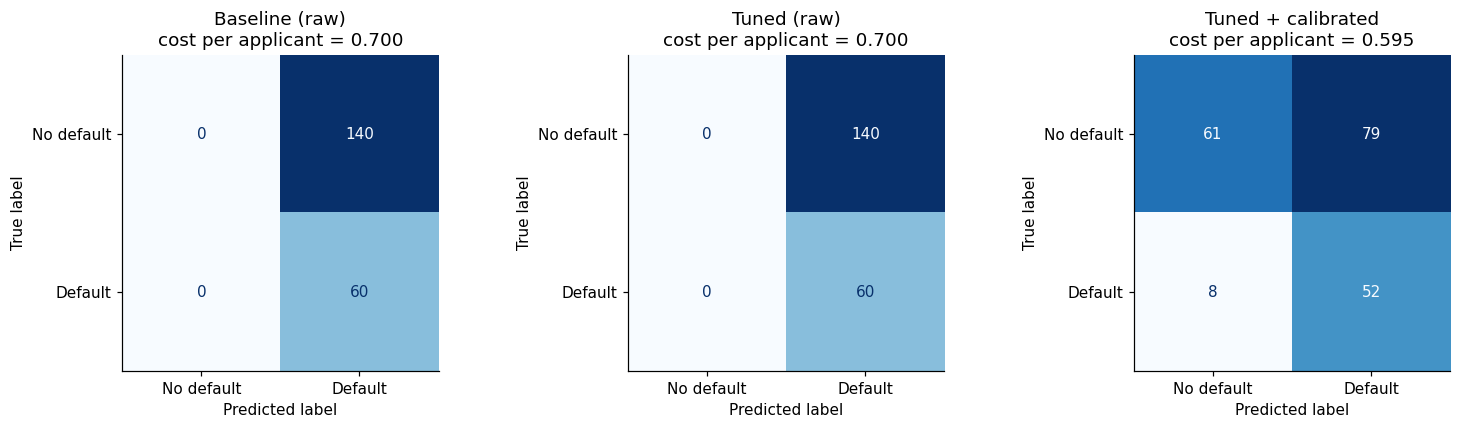

In [13]:
from sklearn.metrics import RocCurveDisplay

# P(default) and 1/6 decisions on the test set for each variation
predictions_ada = {}
for name, model in [("Baseline (raw)", ada_base), ("Tuned (raw)", ada_best), ("Tuned + calibrated", ada_cal)]:
    prob = model.predict_proba(x_test_ada)[:, 1]
    predictions_ada[name] = (prob, (prob > THRESHOLD).astype(int))

# Held-out ROC curves, all on one plot
fig, ax = plt.subplots(figsize=(6, 5))
for name, (prob, labels) in predictions_ada.items():
    RocCurveDisplay.from_predictions(y_test_ada, prob, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)   # random guessing
ax.set_title("AdaBoost: held-out ROC curves")
plt.tight_layout()
plt.show()

# Confusion matrices at cutoff 1/6, one per variation
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, (prob, labels)) in zip(axes, predictions_ada.items()):
    # labels=[0, 1] keeps a 2x2 matrix even when a model predicts only one class
    ConfusionMatrixDisplay.from_predictions(y_test_ada, labels, labels=[0, 1],
                                            display_labels=["No default", "Default"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.grid(False)
    ax.set_title(f"{name}\ncost per applicant = {cost_per_applicant(y_test_ada, labels):.3f}")
plt.tight_layout()
plt.show()

### 8) Feature importance
`feature_importances_` measures how much each feature's splits reduce the error, weighted by each tree's vote. The values sum to 1. Each one-hot level is counted separately (e.g. `checking_< 0 DM`).

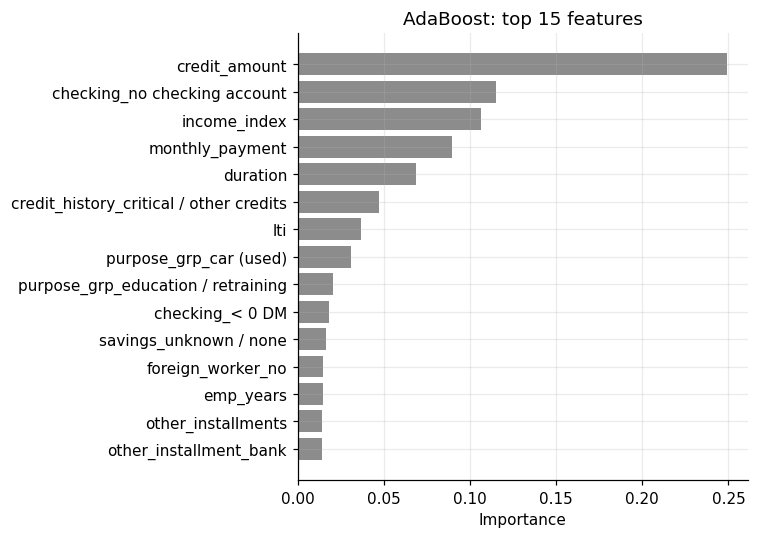

Features with zero importance: 33 of 65


In [19]:
# Importances come from the tuned (uncalibrated) model; calibration does not change which features are used
importance_ada = pd.Series(ada_best.feature_importances_, index=x_train_ada.columns).sort_values()
top15 = importance_ada.tail(15)

plt.figure(figsize=(7, 5))
plt.barh(top15.index, top15.values, color=C_NEUTRAL)
plt.xlabel("Importance")
plt.title("AdaBoost: top 15 features")
plt.tight_layout()
plt.show()

print(f"Features with zero importance: {(importance_ada == 0).sum()} of {len(importance_ada)}")

### 9) SHAP Analysis 

PermutationExplainer explainer: 201it [31:33,  9.47s/it]                         


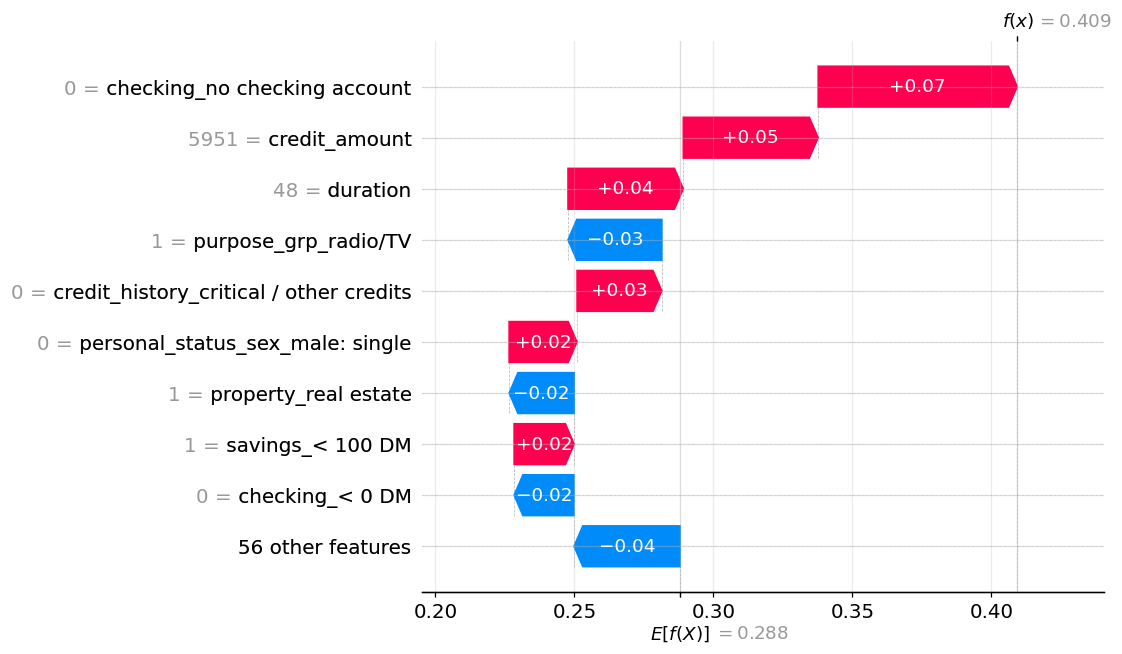

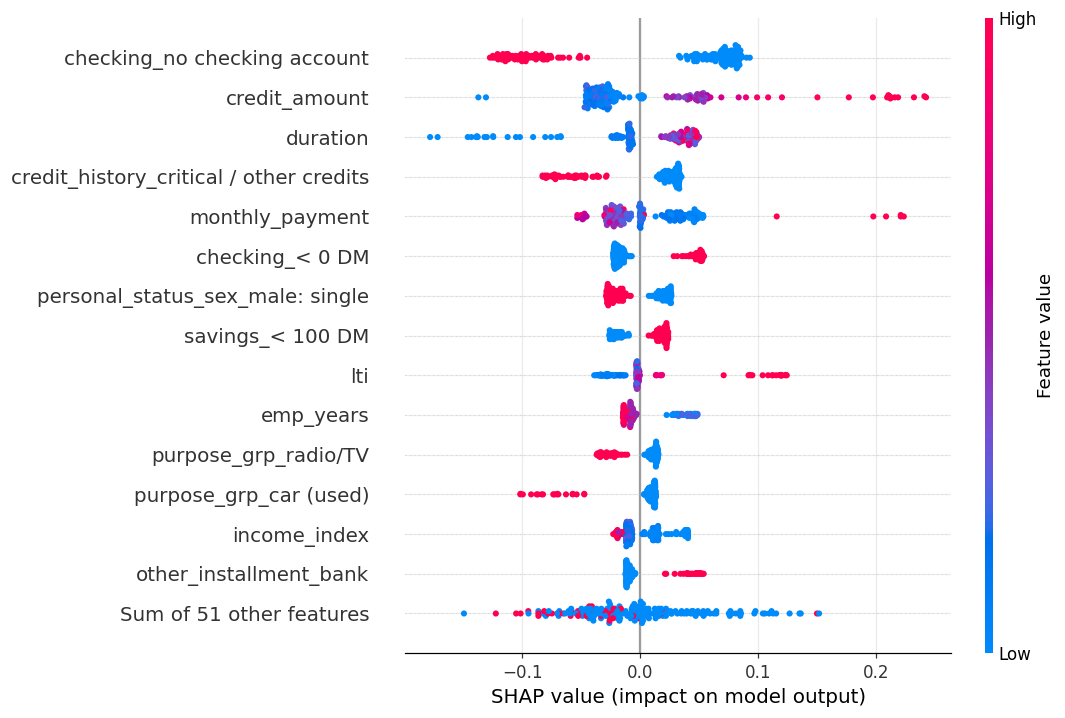

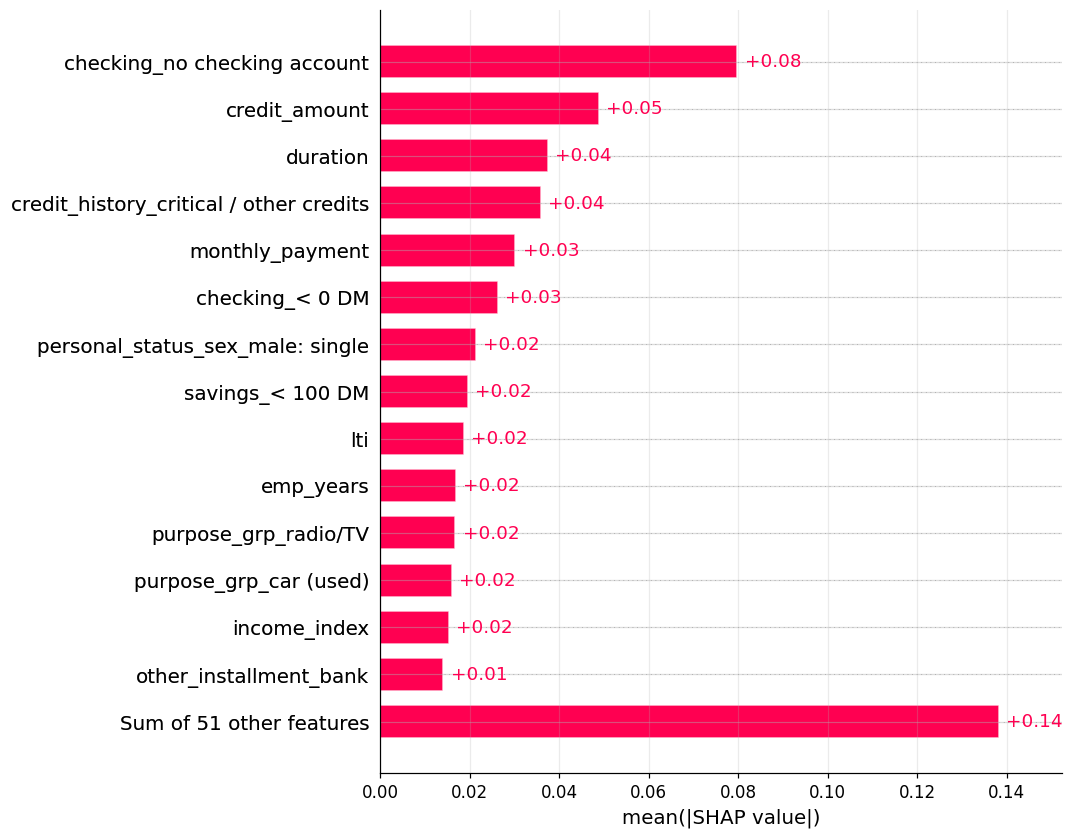

In [15]:
import shap

# SHAP explains the calibrated P(default). AdaBoost isn't supported by SHAP's fast tree method,
# so it uses the slower permutation method (~10 s per applicant; set N_EXPLAIN = 20 to test quickly)
explainer_ada = shap.Explainer(lambda X: ada_cal.predict_proba(X)[:, 1],      # model output to explain
                               shap.sample(x_train_ada, 100, random_state=42))  # baseline: 100 training rows
N_EXPLAIN = 200
sv_ada = explainer_ada(x_test_ada.iloc[:N_EXPLAIN])

shap.plots.waterfall(sv_ada[0], max_display=10)   # why one applicant got their prediction
shap.plots.beeswarm(sv_ada, max_display=15)        # which features matter most, and in which direction
shap.plots.bar(sv_ada, max_display=15)  

In [16]:
# Sum SHAP values of all dummy columns that come from the same original variable (applicant 0)
group_of_ada = {c: next((v for v in cat_features_ada if c.startswith(v + "_")), c) for c in x_test_ada.columns}
row_ada = pd.Series(sv_ada.values[0], index=x_test_ada.columns)
print(row_ada.groupby(group_of_ada).sum().sort_values(key=abs, ascending=False).head(8).round(3))


checking               0.050
credit_amount          0.049
duration               0.041
purpose_grp           -0.035
savings                0.031
personal_status_sex    0.027
property              -0.026
credit_history         0.025
dtype: float64


Applicant 36: P(default) = 0.092 -> approved, actually good


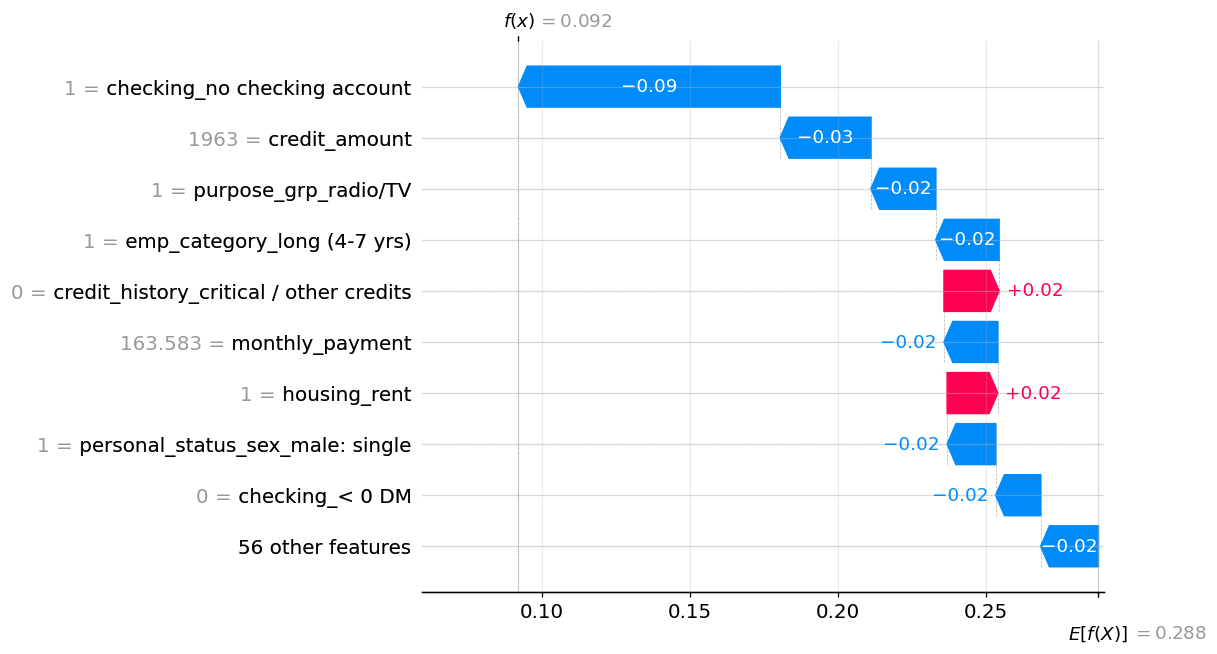

checking              -0.104
credit_amount         -0.031
housing                0.027
emp_category          -0.023
purpose_grp           -0.023
savings                0.019
personal_status_sex   -0.018
monthly_payment       -0.018
dtype: float64


In [17]:
# Second waterfall: a correctly approved good borrower (true negative), closest to the median score
p_ada = ada_cal.predict_proba(x_test_ada.iloc[:N_EXPLAIN])[:, 1]
y_ada0 = y_test_ada.iloc[:N_EXPLAIN].values
tn_ada = np.where((y_ada0 == 0) & (p_ada <= THRESHOLD))[0]          # actual good, approved at 1/6
i_good_ada = tn_ada[np.argmin(np.abs(p_ada[tn_ada] - np.median(p_ada[tn_ada])))]

print(f"Applicant {i_good_ada}: P(default) = {p_ada[i_good_ada]:.3f} -> approved, actually good")
shap.plots.waterfall(sv_ada[i_good_ada], max_display=10)

# Same applicant, with each variable's dummy columns added together (for the report text)
group_of_ada = {c: next((v for v in cat_features_ada if c.startswith(v + "_")), c) for c in x_test_ada.columns}
row_good = pd.Series(sv_ada.values[i_good_ada], index=x_test_ada.columns)
print(row_good.groupby(group_of_ada).sum().sort_values(key=abs, ascending=False).head(8).round(3))


### Summary of AdaBoost

| Step | Result |
|---|---|
| Features | 26 columns, 65 after one-hot encoding; 800 train / 200 test |
| Baseline (100 stumps, learning rate 1.0) | test accuracy 0.755, AUC 0.777 |
| Tuned (5-fold CV on train) | stumps, learning rate 0.5, 400 rounds; CV AUC 0.796 |
| Train vs test error (0.5 cutoff) | 0.210 vs 0.255: some overfitting, but test error is still well below the 30% of "predict all good" |
| Calibration | P(default) range 0.26-0.61 raw, 0.01-0.88 after sigmoid calibration |
| Test AUC (calibrated) | 0.799 |
| Test at cutoff 1/6 | catches 52 of 60 bad borrowers (recall 0.87), but rejects 79 of 140 good ones; accuracy 0.565 |
| Cost per applicant | **0.595** at 1/6, vs 0.880 at the 0.5 cutoff, 0.700 rejecting everyone, 1.500 approving everyone |